# Intraday (1-Minute) Stock Price Prediction

Predicts the next-minute percentage price change for AAPL, MSFT, GOOGL, AMZN and NVDA from 5 trading days of 1-minute data, using technical indicators (MA, RSI, MACD) and comparing Ridge regression, Random Forest and an LSTM network.

# Extract data from Yahoo Finance

In [2]:
import yfinance as yf
import pandas as pd
from datetime import datetime, timedelta
import numpy as np

tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA']
end_date = datetime.now()
start_date = end_date - timedelta(days=7)
data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    interval='1m',
    group_by='ticker'
)

<ipython>:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(
[*********************100%***********************]  5 of 5 completed


# Preprocess the data by handling missing values

#### Preprocessing Fuction

In [3]:
def clean_data(df, ticker):
    if ticker in df.columns.get_level_values(0):
        stock_df = df[ticker].copy()
    else:
        print(f"{ticker}not exist")
        return None
        
    stock_df['Ticker'] = ticker
    stock_df = stock_df.reset_index()
    stock_df = stock_df.dropna()
    
    return stock_df

### Preprocessing

In [4]:
cleaned_data = {}
for ticker in tickers:
    cleaned_df = clean_data(data, ticker)
    if cleaned_df is not None:
        cleaned_data[ticker] = cleaned_df

# Storing data

In [5]:
if cleaned_data:
    all_stocks = pd.concat(cleaned_data.values(), ignore_index=True)
    all_stocks.to_csv('stock_data_1min_cleaned.csv', index=False)

# Read data 

In [6]:
import matplotlib.pyplot as plt

df = pd.read_csv('stock_data_1min_cleaned.csv', parse_dates=['Datetime'])
tickers = df['Ticker'].unique()

# Calculate the moving averages, RSI, and MACD for each ticker

In [7]:
 all_dfs = []

for ticker in tickers:
    ticker_df = df[df['Ticker'] == ticker].copy()
    ticker_df.sort_values('Datetime', inplace=True)
    ticker_df.set_index('Datetime', inplace=True)
    
    # short-term moving averages
    ticker_df['MA_5'] = ticker_df['Close'].rolling(window=5).mean()
    ticker_df['MA_20'] = ticker_df['Close'].rolling(window=20).mean()

    # RSI
    def calculate_rsi(data, window=14):
        delta = data.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi

    ticker_df['RSI_14'] = calculate_rsi(ticker_df['Close'])

    # MACD
    def calculate_macd(data, fast=12, slow=26, signal=9):
        ema_fast = data.ewm(span=fast).mean()
        ema_slow = data.ewm(span=slow).mean()
        macd = ema_fast - ema_slow
        macd_signal = macd.ewm(span=signal).mean()
        macd_histogram = macd - macd_signal
        return macd, macd_signal, macd_histogram

    macd_values = calculate_macd(ticker_df['Close'])
    ticker_df['MACD'] = macd_values[0]
    ticker_df['MACD_Signal'] = macd_values[1]
    ticker_df['MACD_Histogram'] = macd_values[2]
    
    ticker_df.reset_index(inplace=True)
    ticker_df['Ticker'] = ticker  
    
    all_dfs.append(ticker_df)
    
combined_df = pd.concat(all_dfs, ignore_index=True)
 combined_df.to_csv('all_stocks_with_indicators.csv', index=False)

# Create separate charts for each stock

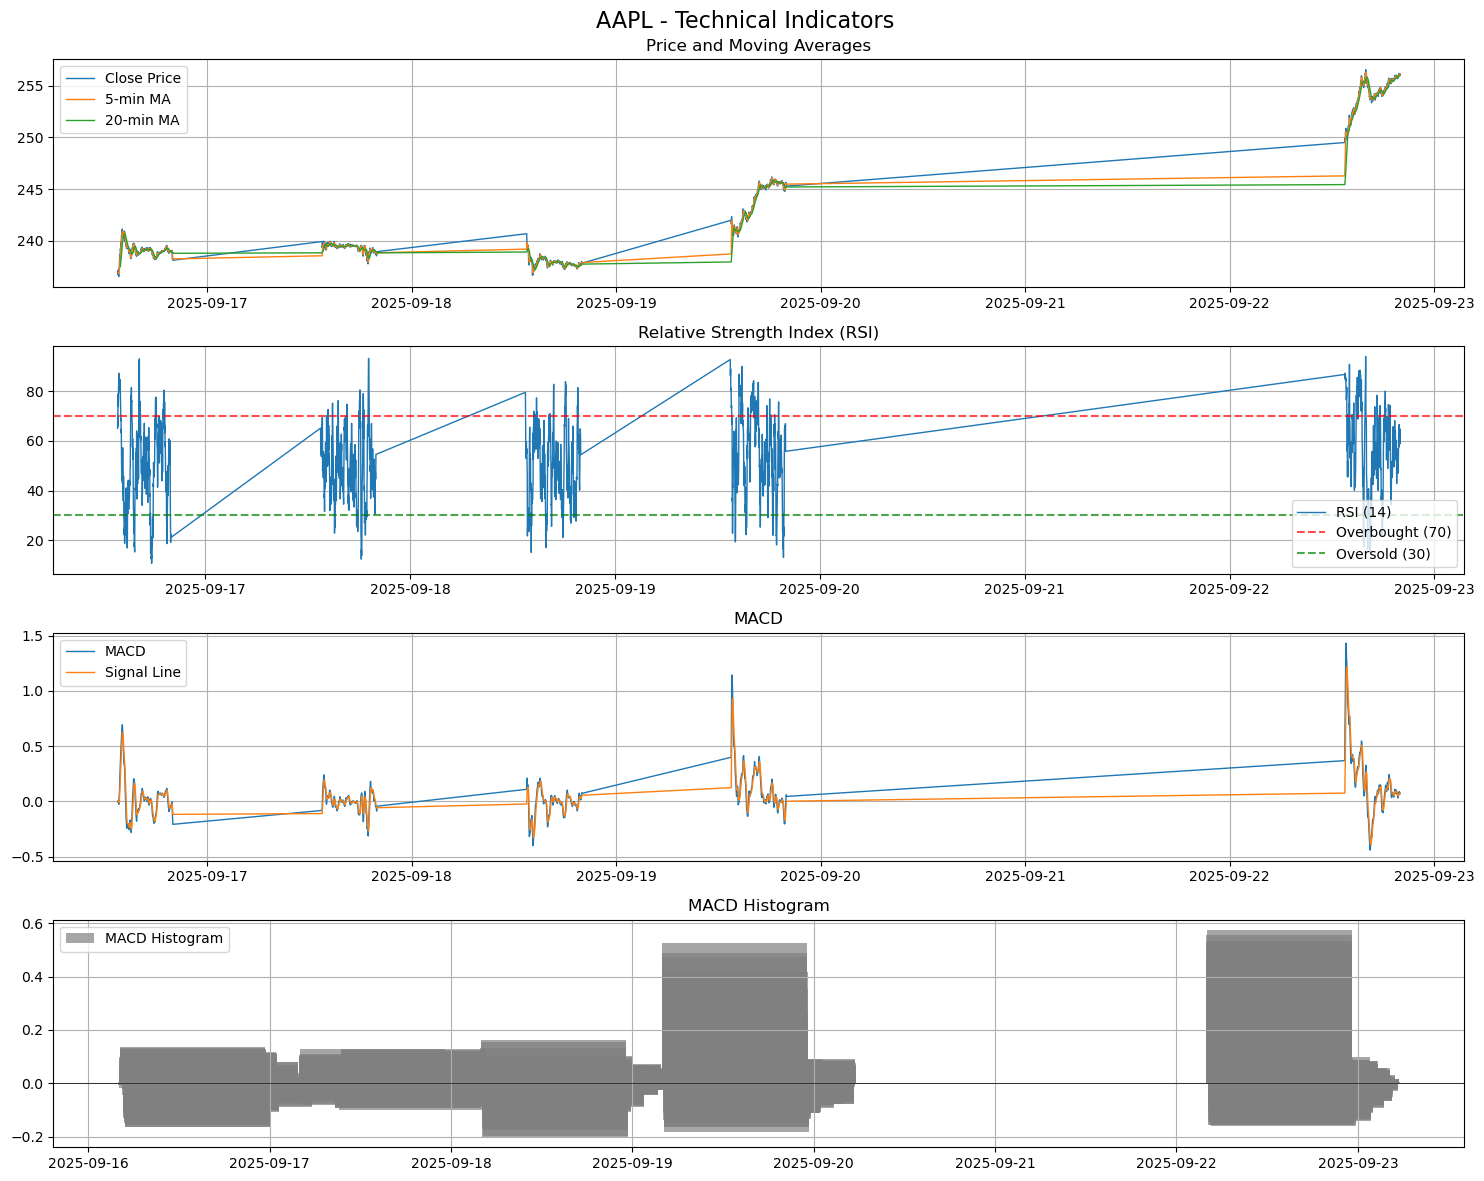

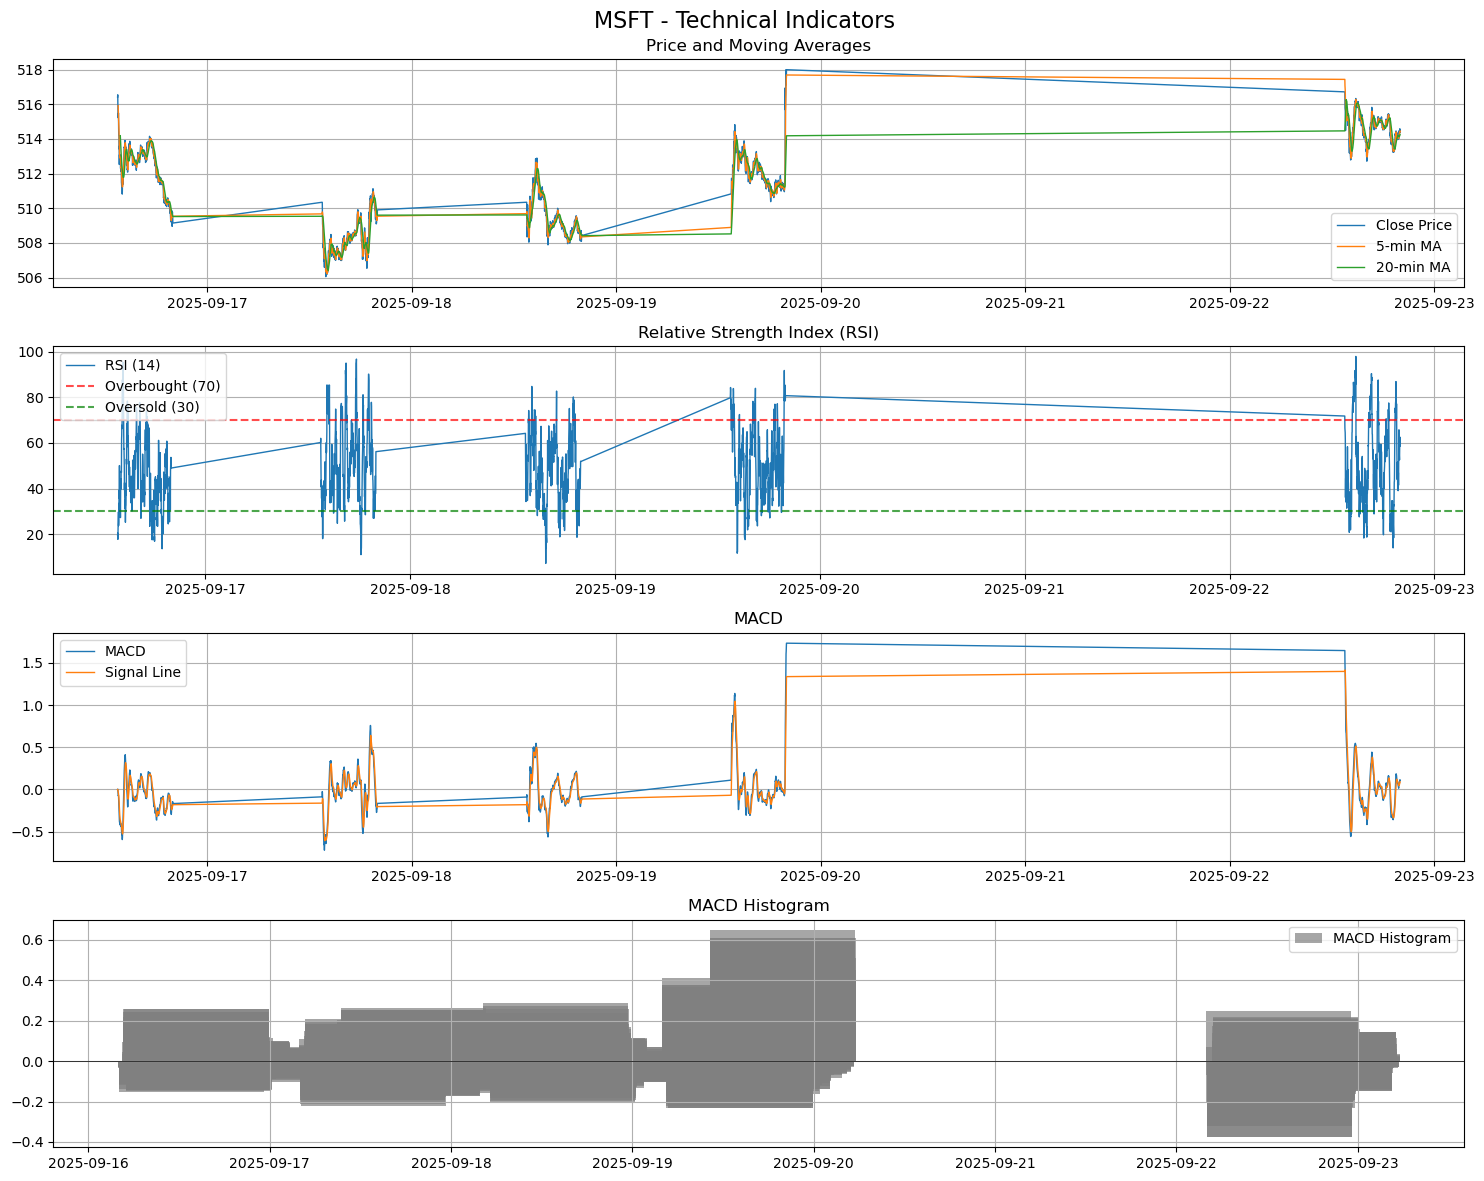

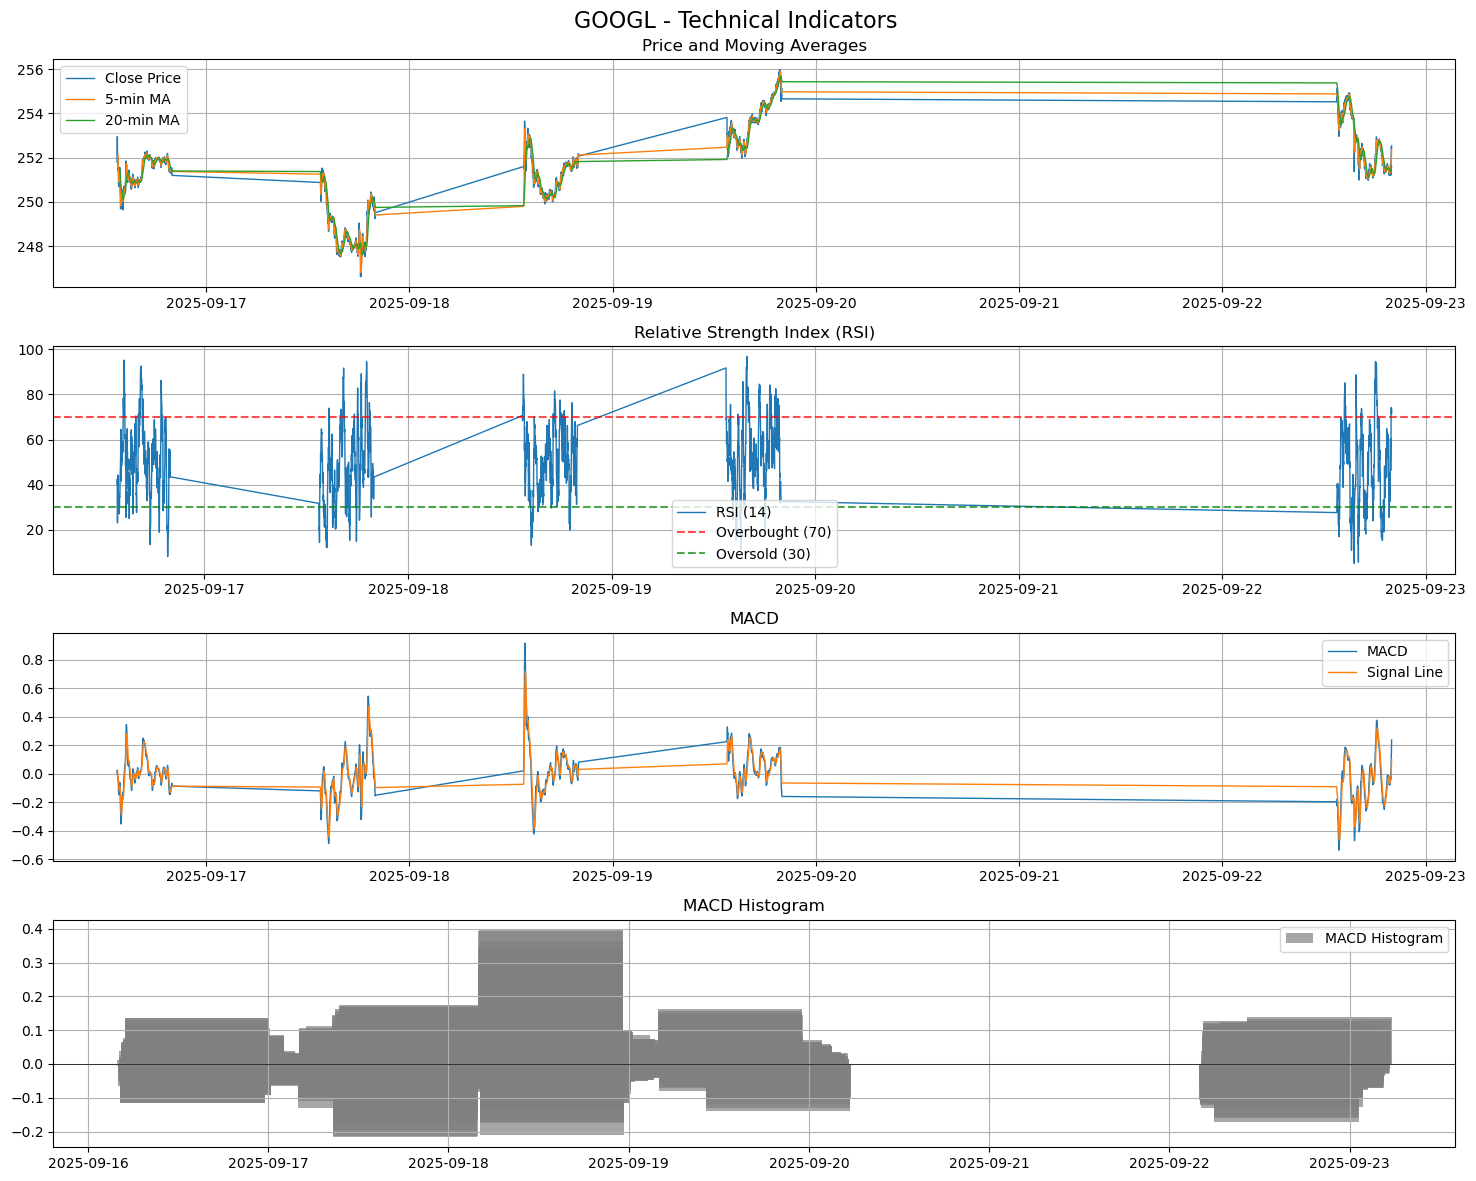

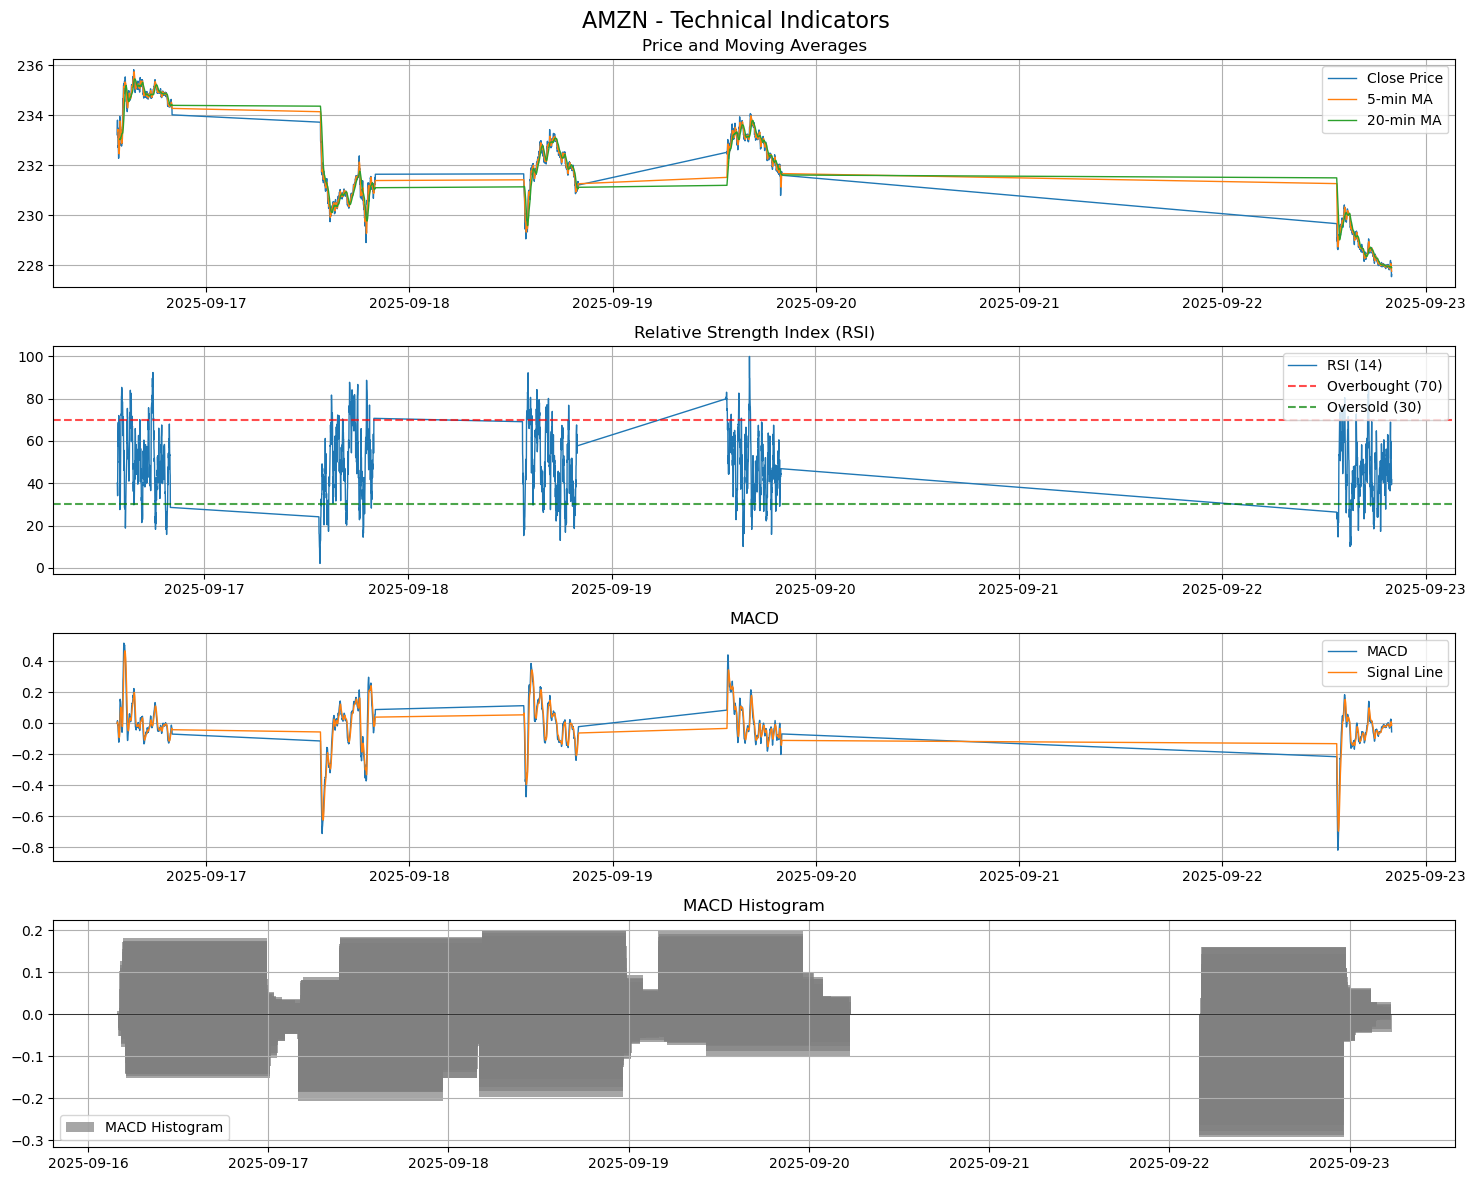

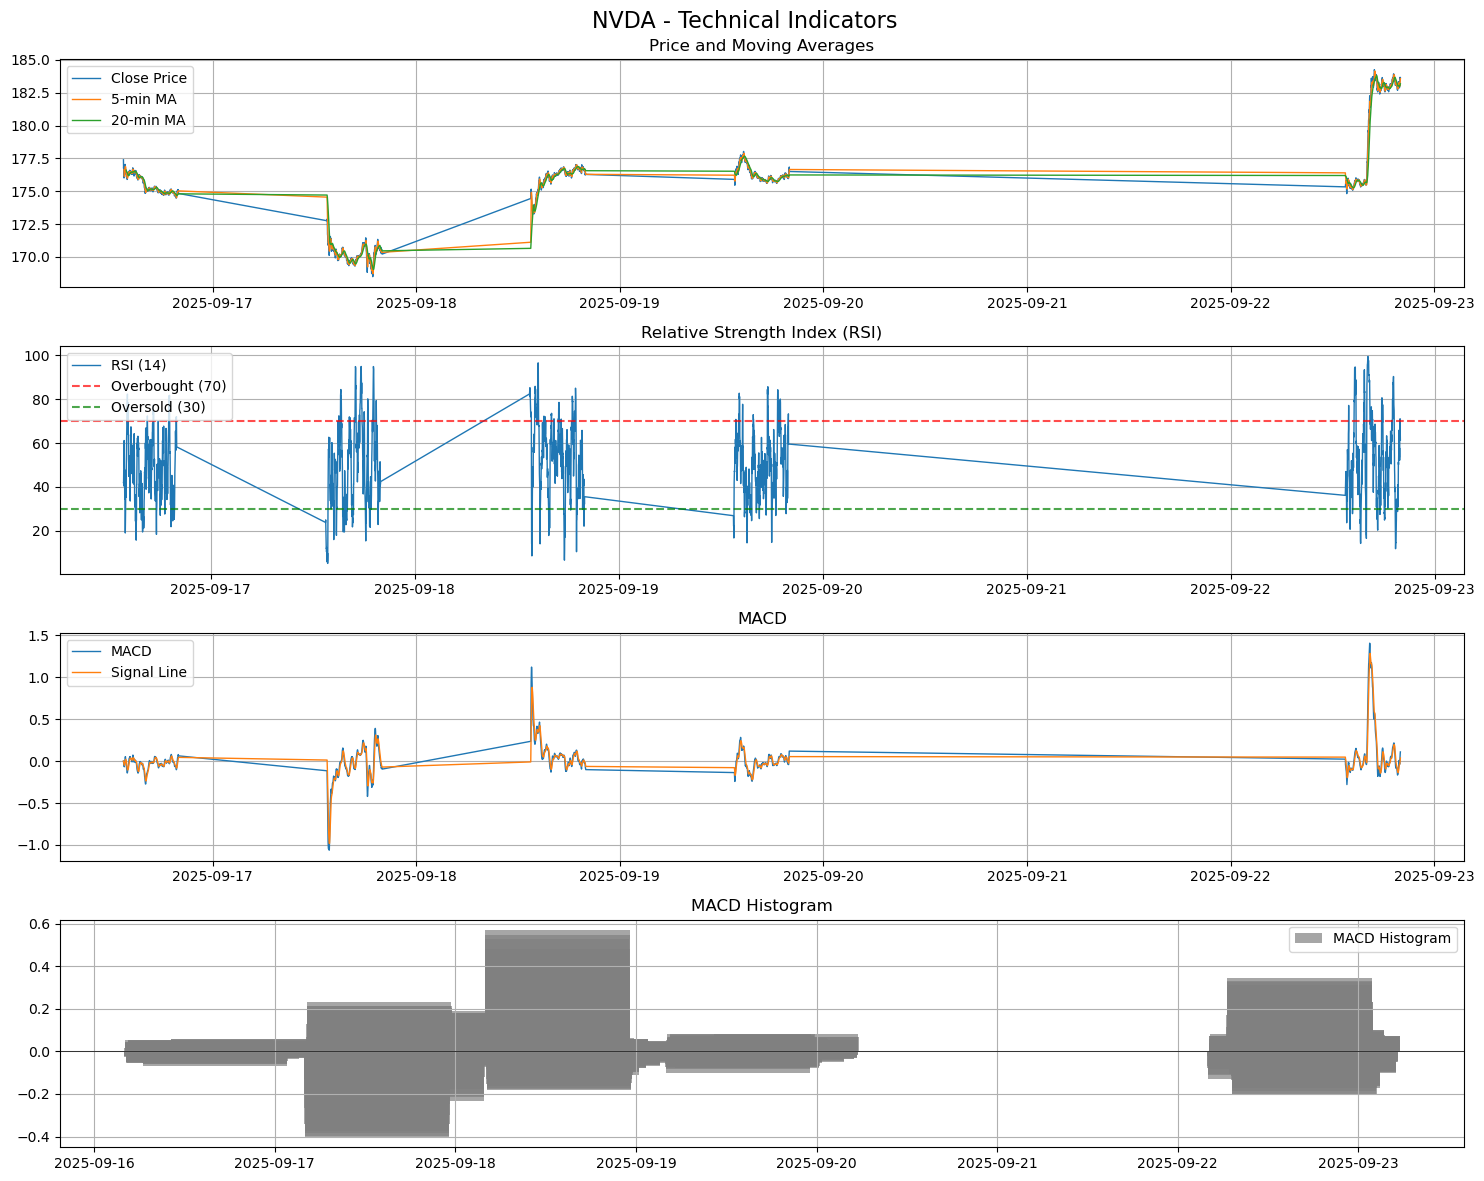

In [8]:
for ticker in tickers:
    ticker_df = combined_df[combined_df['Ticker'] == ticker].copy()
    ticker_df.set_index('Datetime', inplace=True)
    
    plt.figure(figsize=(15, 12))
    plt.suptitle(f'{ticker} - Technical Indicators', fontsize=16)
    
    # Price and moving averages
    plt.subplot(4, 1, 1)
    plt.plot(ticker_df.index, ticker_df['Close'], label='Close Price', linewidth=1)
    plt.plot(ticker_df.index, ticker_df['MA_5'], label='5-min MA', linewidth=1)
    plt.plot(ticker_df.index, ticker_df['MA_20'], label='20-min MA', linewidth=1)
    plt.title('Price and Moving Averages')
    plt.legend()
    plt.grid(True)
    
    # RSI
    plt.subplot(4, 1, 2)
    plt.plot(ticker_df.index, ticker_df['RSI_14'], label='RSI (14)', linewidth=1)
    plt.axhline(70, color='r', linestyle='--', alpha=0.7, label='Overbought (70)')
    plt.axhline(30, color='g', linestyle='--', alpha=0.7, label='Oversold (30)')
    plt.title('Relative Strength Index (RSI)')
    plt.legend()
    plt.grid(True)
    
    # MACD
    plt.subplot(4, 1, 3)
    plt.plot(ticker_df.index, ticker_df['MACD'], label='MACD', linewidth=1)
    plt.plot(ticker_df.index, ticker_df['MACD_Signal'], label='Signal Line', linewidth=1)
    plt.title('MACD')
    plt.legend()
    plt.grid(True)
    
    # MACD Histogram
    plt.subplot(4, 1, 4)
    plt.bar(ticker_df.index, ticker_df['MACD_Histogram'], label='MACD Histogram', color='gray', alpha=0.7)
    plt.axhline(0, color='black', linewidth=0.5)
    plt.title('MACD Histogram')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(f'{ticker}_technical_indicators.png')
    plt.show()

# Model Training

### Preparation

In [9]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import warnings


warnings.filterwarnings('ignore')

df = pd.read_csv('all_stocks_with_indicators.csv', parse_dates=['Datetime'])


tickers = df['Ticker'].unique()

feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 
                   'MA_5', 'MA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Histogram']

all_models = {}
all_results = {}

### Preprocessing and Model Training

Training Ridge Regression model...
Training Random Forest model...
Training LSTM model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step 

AAPL Model Performance:
Ridge Regression - MSE: 0.005048, MAE: 0.051256, R²: -0.115141, Direction Accuracy: 0.5466
Random Forest - MSE: 0.007305, MAE: 0.060565, R²: -0.613686, Direction Accuracy: 0.4352
LSTM - MSE: 0.004333, MAE: 0.048788, R²: -0.072717, Direction Accuracy: 0.5266
AAPL Best Model: lstm
Training Ridge Regression model...
Training Random Forest model...
Training LSTM model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step 

MSFT Model Performance:
Ridge Regression - MSE: 0.001479, MAE: 0.027996, R²: -0.020928, Direction Accuracy: 0.5233
Random Forest - MSE: 0.004103, MAE: 0.053904, R²: -1.832193, Direction Accuracy: 0.5104
LSTM - MSE: 0.001362, MAE: 0.027655, R²: -0.051745, Direction Accuracy: 0.5160
MSFT Best Model: lstm
Training Ridge Regression model...
Training Random Forest model...
Training LSTM model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/ste

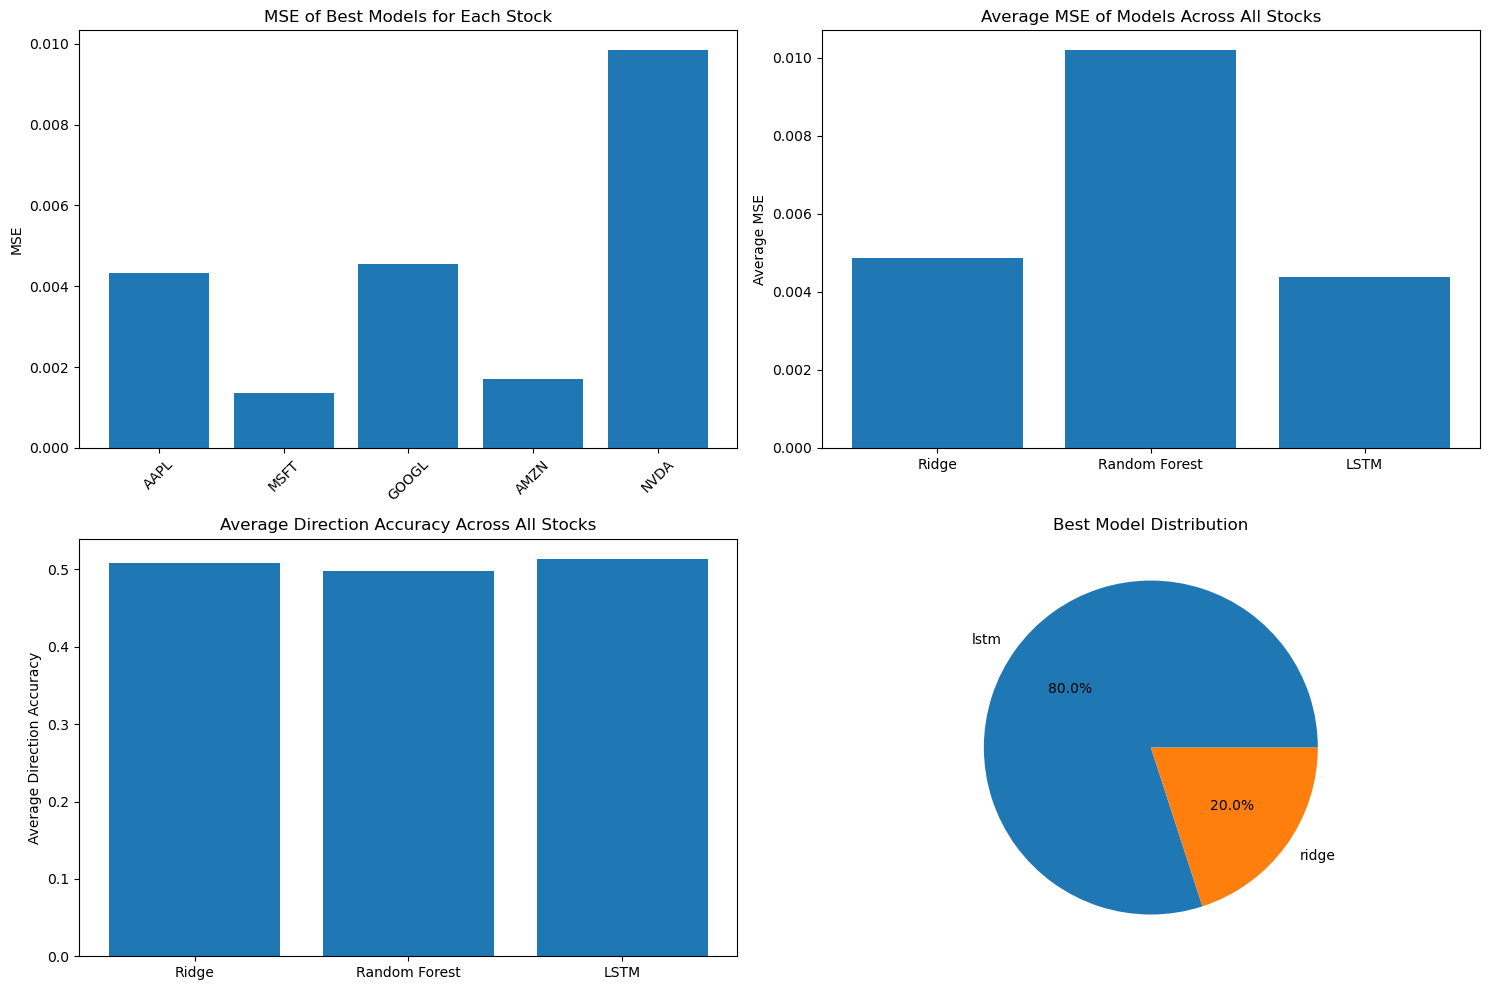


Future One-Minute Price Change Prediction


AAPL: Predicted next minute price change 0.0243% (using lstm model)
MSFT: Predicted next minute price change 0.0078% (using lstm model)
GOOGL: Predicted next minute price change 0.0035% (using lstm model)
AMZN: Predicted next minute price change -0.0019% (using ridge model)
NVDA: Predicted next minute price change -0.0133% (using lstm model)



All models saved to 'stock_models' directory


In [10]:
for ticker in tickers:
    
    ticker_df = df[df['Ticker'] == ticker].copy()
    ticker_df.sort_values('Datetime', inplace=True)

    ticker_df['Target'] = ticker_df['Close'].shift(-1) - ticker_df['Close']
    ticker_df['Target_Pct'] = ticker_df['Target'] / ticker_df['Close'] * 100
    
    ticker_df.dropna(inplace=True)
    
    X = ticker_df[feature_columns]
    y = ticker_df['Target_Pct']
    
    split_idx = int(len(X) * 0.8)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]
    
    scaler = StandardScaler()  
    X_train_scaled = scaler.fit_transform(X_train)  
    X_test_scaled = scaler.transform(X_test)  
    
    
    ticker_models = {}

    # Ridge Regression
    print("Training Ridge Regression model...")
    ridge_params = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
    ridge_model = GridSearchCV(Ridge(), ridge_params, cv=5, scoring='neg_mean_squared_error')
    ridge_model.fit(X_train_scaled, y_train)
    
    best_ridge_model = Ridge(alpha=ridge_model.best_params_['alpha'])
    best_ridge_model.fit(X_train_scaled, y_train)
    y_pred_ridge = best_ridge_model.predict(X_test_scaled)
    
    # Random Forest model
    print("Training Random Forest model...")
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train_scaled, y_train)
    y_pred_rf = rf_model.predict(X_test_scaled)
    
    # LSTM model (only if enough data)
    if len(X_train) > 100:  # Ensure enough data for LSTM training
        print("Training LSTM model...")
        # Prepare LSTM data (requires sequential data)
        def create_sequences(data, target, sequence_length=10):
            X_seq, y_seq = [], []
            for i in range(len(data) - sequence_length):
                X_seq.append(data[i:i+sequence_length])
                y_seq.append(target[i+sequence_length])
            return np.array(X_seq), np.array(y_seq)
        
        sequence_length = 10
        X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train.values, sequence_length)
        X_test_seq, y_test_seq = create_sequences(X_test_scaled, y_test.values, sequence_length)
        
        # Build LSTM model
        lstm_model = Sequential([
            LSTM(50, return_sequences=True, input_shape=(sequence_length, X_train_scaled.shape[1])),
            Dropout(0.2),
            LSTM(50, return_sequences=False),
            Dropout(0.2),
            Dense(25),
            Dense(1)
        ])
        
        lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
        history = lstm_model.fit(X_train_seq, y_train_seq, 
                                 batch_size=32, 
                                 epochs=30, 
                                 validation_data=(X_test_seq, y_test_seq),
                                 verbose=0)
        
        # Make predictions with LSTM
        y_pred_lstm = lstm_model.predict(X_test_seq).flatten()
        y_test_for_lstm = y_test_seq
    else:
        print("Insufficient data, skipping LSTM training")
        lstm_model = None
        y_pred_lstm = None
        y_test_for_lstm = None
    
    # Evaluate models
    def evaluate_model(y_true, y_pred, model_name):
        mse = mean_squared_error(y_true, y_pred)
        mae = mean_absolute_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        
        # Calculate direction accuracy (whether prediction direction is correct)
        direction_accuracy = np.mean((np.sign(y_true) == np.sign(y_pred)) | (y_true == 0))
        
        return mse, mae, r2, direction_accuracy
    
    # Evaluate all models
    ridge_metrics = evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
    rf_metrics = evaluate_model(y_test, y_pred_rf, "Random Forest")
    
    if lstm_model is not None:
        lstm_metrics = evaluate_model(y_test_for_lstm, y_pred_lstm, "LSTM")
    else:
        lstm_metrics = (np.inf, np.inf, -np.inf, 0)  # Set to worst values
    
    # Store models and results
    ticker_models = {
        'ridge': best_ridge_model,
        'rf': rf_model,
        'lstm': lstm_model,
        'scaler': scaler
    }
    
    ticker_results = {
        'ridge_metrics': ridge_metrics,
        'rf_metrics': rf_metrics,
        'lstm_metrics': lstm_metrics,
        'X_test': X_test,
        'y_test': y_test
    }
    
    all_models[ticker] = ticker_models
    all_results[ticker] = ticker_results
    
    # Print current stock results
    print(f"\n{ticker} Model Performance:")
    print(f"Ridge Regression - MSE: {ridge_metrics[0]:.6f}, MAE: {ridge_metrics[1]:.6f}, R²: {ridge_metrics[2]:.6f}, Direction Accuracy: {ridge_metrics[3]:.4f}")
    print(f"Random Forest - MSE: {rf_metrics[0]:.6f}, MAE: {rf_metrics[1]:.6f}, R²: {rf_metrics[2]:.6f}, Direction Accuracy: {rf_metrics[3]:.4f}")
    if lstm_model is not None:
        print(f"LSTM - MSE: {lstm_metrics[0]:.6f}, MAE: {lstm_metrics[1]:.6f}, R²: {lstm_metrics[2]:.6f}, Direction Accuracy: {lstm_metrics[3]:.4f}")
    
    # Select best model
    model_performance = {
        'ridge': ridge_metrics[0],
        'rf': rf_metrics[0],
        'lstm': lstm_metrics[0] if lstm_model is not None else np.inf
    }
    best_model_name = min(model_performance, key=model_performance.get)
    
    print(f"{ticker} Best Model: {best_model_name}")

# Summarize results for all stocks
print(f"\n{'='*60}")
print("Summary of Model Performance for All Stocks")
print(f"{'='*60}")

summary_data = []
for ticker in all_results:
    ridge_metrics = all_results[ticker]['ridge_metrics']
    rf_metrics = all_results[ticker]['rf_metrics']
    lstm_metrics = all_results[ticker]['lstm_metrics']
    
    # Select best model
    model_performance = {
        'ridge': ridge_metrics[0],
        'rf': rf_metrics[0],
        'lstm': lstm_metrics[0]
    }
    best_model_name = min(model_performance, key=model_performance.get)
    
    summary_data.append({
        'Ticker': ticker,
        'Ridge_MSE': ridge_metrics[0],
        'Ridge_MAE': ridge_metrics[1],
        'Ridge_R2': ridge_metrics[2],
        'Ridge_Direction': ridge_metrics[3],
        'RF_MSE': rf_metrics[0],
        'RF_MAE': rf_metrics[1],
        'RF_R2': rf_metrics[2],
        'RF_Direction': rf_metrics[3],
        'LSTM_MSE': lstm_metrics[0],
        'LSTM_MAE': lstm_metrics[1],
        'LSTM_R2': lstm_metrics[2],
        'LSTM_Direction': lstm_metrics[3],
        'Best_Model': best_model_name
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df)

# Visualize best model performance for all stocks
plt.figure(figsize=(15, 10))

# Compare MSE of best models across stocks
plt.subplot(2, 2, 1)
best_model_mse = []
tickers_list = []
for ticker in all_results:
    model_performance = {
        'ridge': all_results[ticker]['ridge_metrics'][0],
        'rf': all_results[ticker]['rf_metrics'][0],
        'lstm': all_results[ticker]['lstm_metrics'][0]
    }
    best_model_name = min(model_performance, key=model_performance.get)
    best_model_mse.append(model_performance[best_model_name])
    tickers_list.append(ticker)

plt.bar(tickers_list, best_model_mse)
plt.title('MSE of Best Models for Each Stock')
plt.xticks(rotation=45)
plt.ylabel('MSE')

# Average performance of each model across all stocks
plt.subplot(2, 2, 2)
models_avg_mse = {
    'Ridge': summary_df['Ridge_MSE'].mean(),
    'Random Forest': summary_df['RF_MSE'].mean(),
    'LSTM': summary_df['LSTM_MSE'].mean()
}

plt.bar(models_avg_mse.keys(), models_avg_mse.values())
plt.title('Average MSE of Models Across All Stocks')
plt.ylabel('Average MSE')

# Average direction accuracy of each model across all stocks
plt.subplot(2, 2, 3)
models_avg_direction = {
    'Ridge': summary_df['Ridge_Direction'].mean(),
    'Random Forest': summary_df['RF_Direction'].mean(),
    'LSTM': summary_df['LSTM_Direction'].mean()
}

plt.bar(models_avg_direction.keys(), models_avg_direction.values())
plt.title('Average Direction Accuracy Across All Stocks')
plt.ylabel('Average Direction Accuracy')

# Distribution of best models
plt.subplot(2, 2, 4)
best_model_counts = summary_df['Best_Model'].value_counts()
plt.pie(best_model_counts.values, labels=best_model_counts.index, autopct='%1.1f%%')
plt.title('Best Model Distribution')

plt.tight_layout()
plt.show()

# Use best model for future prediction for each stock
print(f"\n{'='*60}")
print("Future One-Minute Price Change Prediction")
print(f"{'='*60}")

for ticker in all_models:
    models = all_models[ticker]
    results = all_results[ticker]
    
    # Select best model
    model_performance = {
        'ridge': results['ridge_metrics'][0],
        'rf': results['rf_metrics'][0],
        'lstm': results['lstm_metrics'][0]
    }
    best_model_name = min(model_performance, key=model_performance.get)
    
    # Get latest data
    latest_data = results['X_test'].iloc[-1:].values
    latest_data_scaled = models['scaler'].transform(latest_data)
    
    # Make prediction using best model
    if best_model_name == 'ridge':
        future_prediction = models['ridge'].predict(latest_data_scaled)[0]
    elif best_model_name == 'rf':
        future_prediction = models['rf'].predict(latest_data_scaled)[0]
    else:  # LSTM
        # Need sequential data
        sequence_length = 10
        # Get recent sequence data
        X_test_scaled = models['scaler'].transform(results['X_test'])
        if len(X_test_scaled) >= sequence_length:
            last_sequence = X_test_scaled[-sequence_length:].reshape(1, sequence_length, -1)
            future_prediction = models['lstm'].predict(last_sequence, verbose=0)[0][0]
        else:
            future_prediction = 0  # Insufficient data
    
    print(f"{ticker}: Predicted next minute price change {future_prediction:.4f}% (using {best_model_name} model)")

# Save models (optional)
import joblib
import os

# Create directory for saving models
if not os.path.exists('stock_models'):
    os.makedirs('stock_models')

# Save models for each stock
for ticker in all_models:
    models = all_models[ticker]
    
    # Save Ridge Regression model
    joblib.dump(models['ridge'], f'stock_models/{ticker}_ridge_model.pkl')
    
    # Save Random Forest model
    joblib.dump(models['rf'], f'stock_models/{ticker}_rf_model.pkl')
    
    # Save scaler
    joblib.dump(models['scaler'], f'stock_models/{ticker}_scaler.pkl')
    
    # Save LSTM model (if exists)
    if models['lstm'] is not None:
        models['lstm'].save(f'stock_models/{ticker}_lstm_model.h5')

print(f"\nAll models saved to 'stock_models' directory")

# Create visualizations 


Creating visualizations for AAPL...


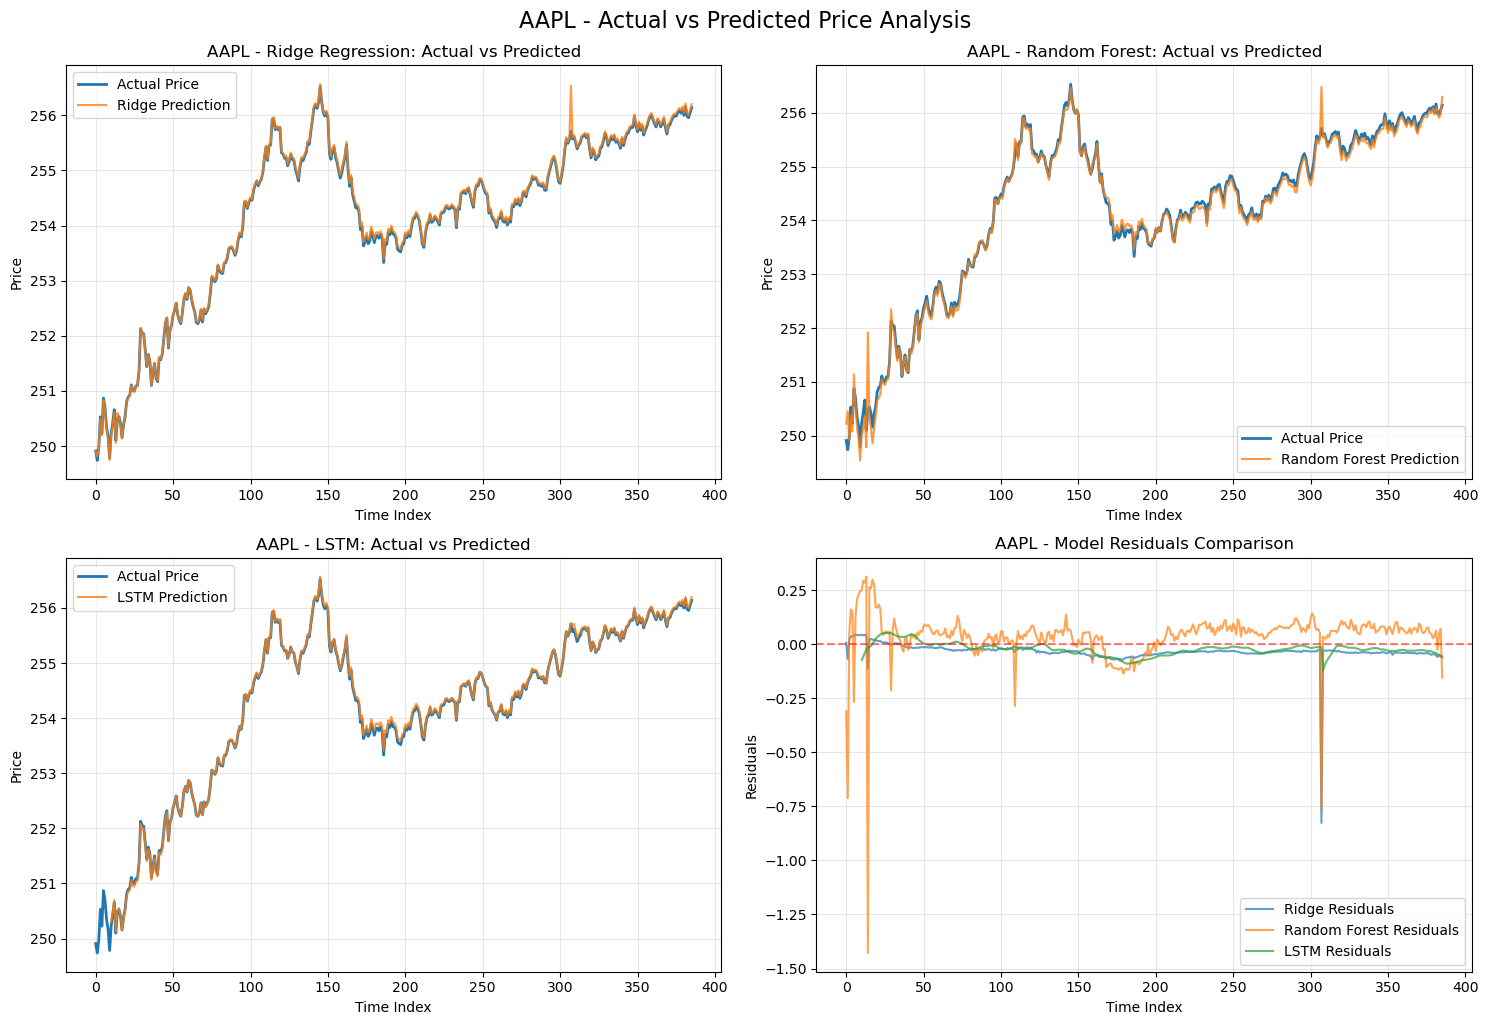

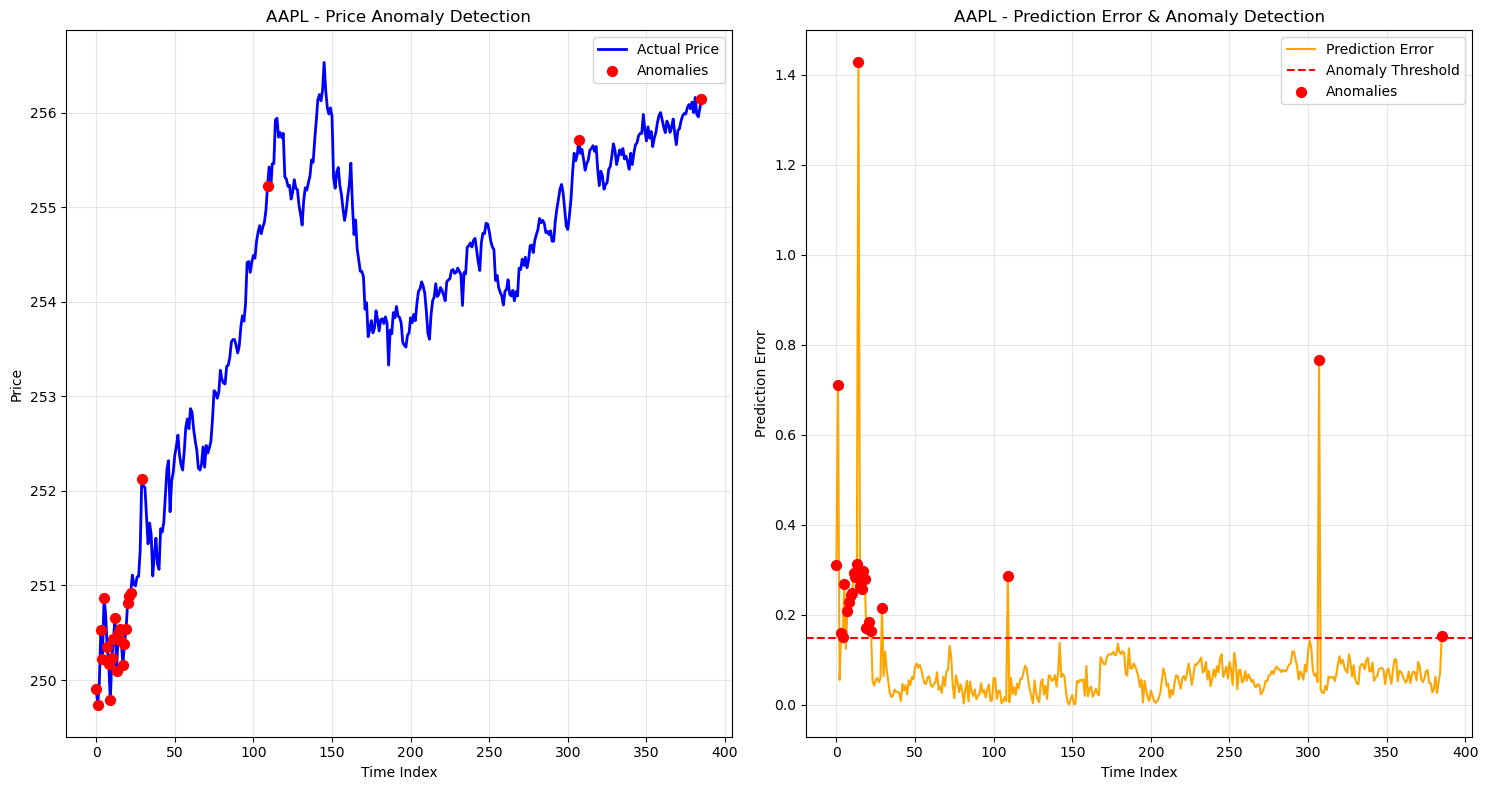

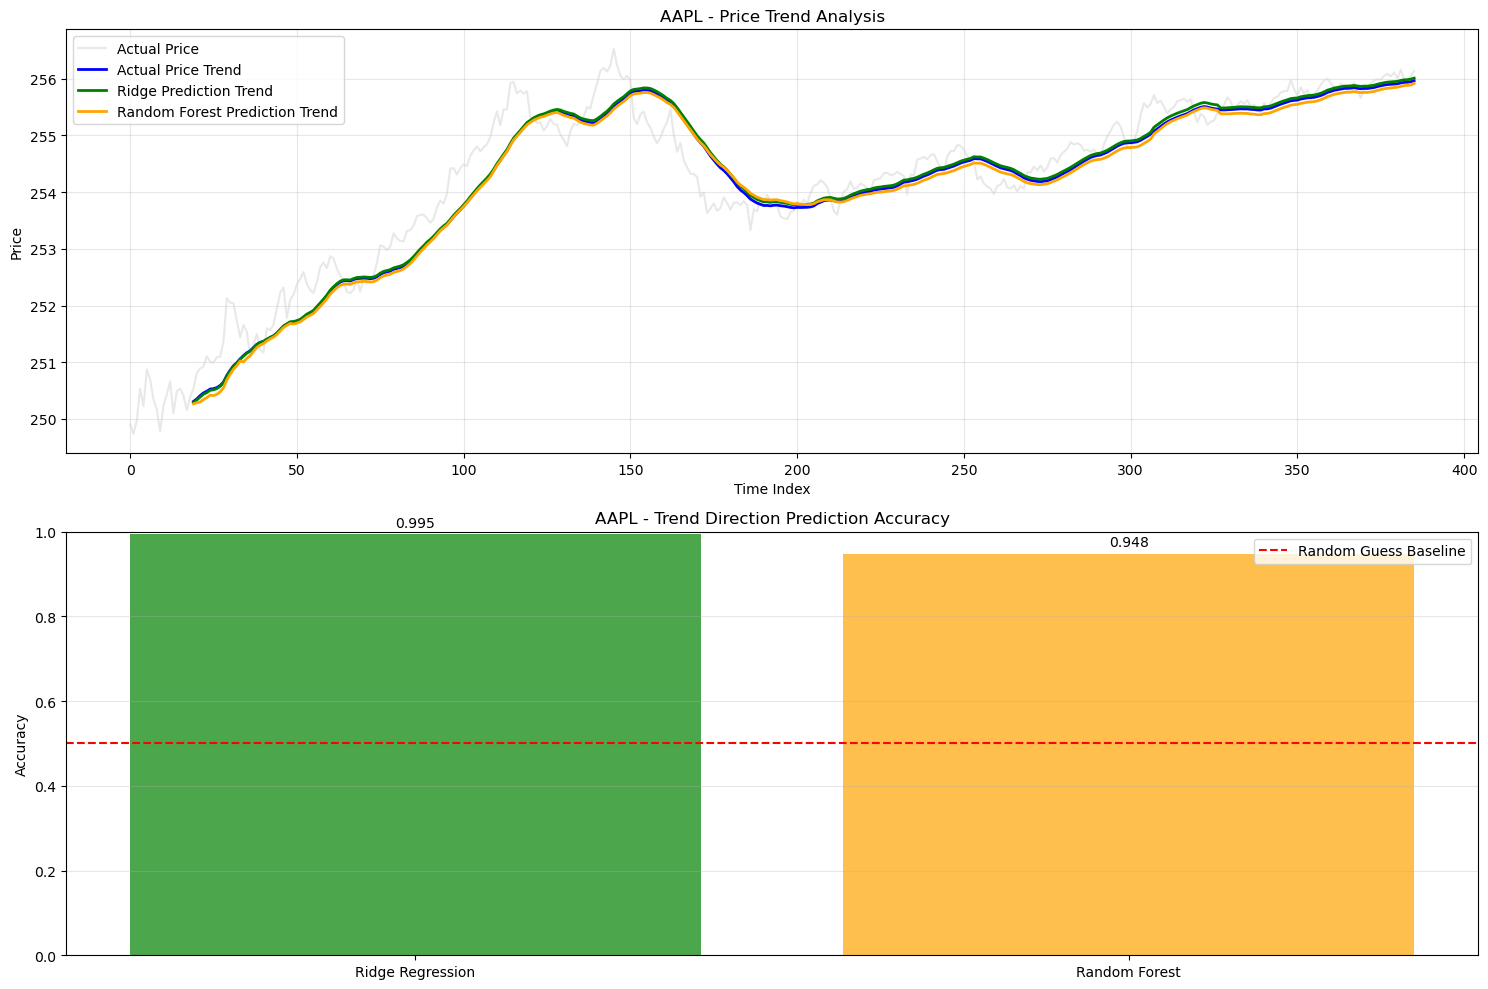

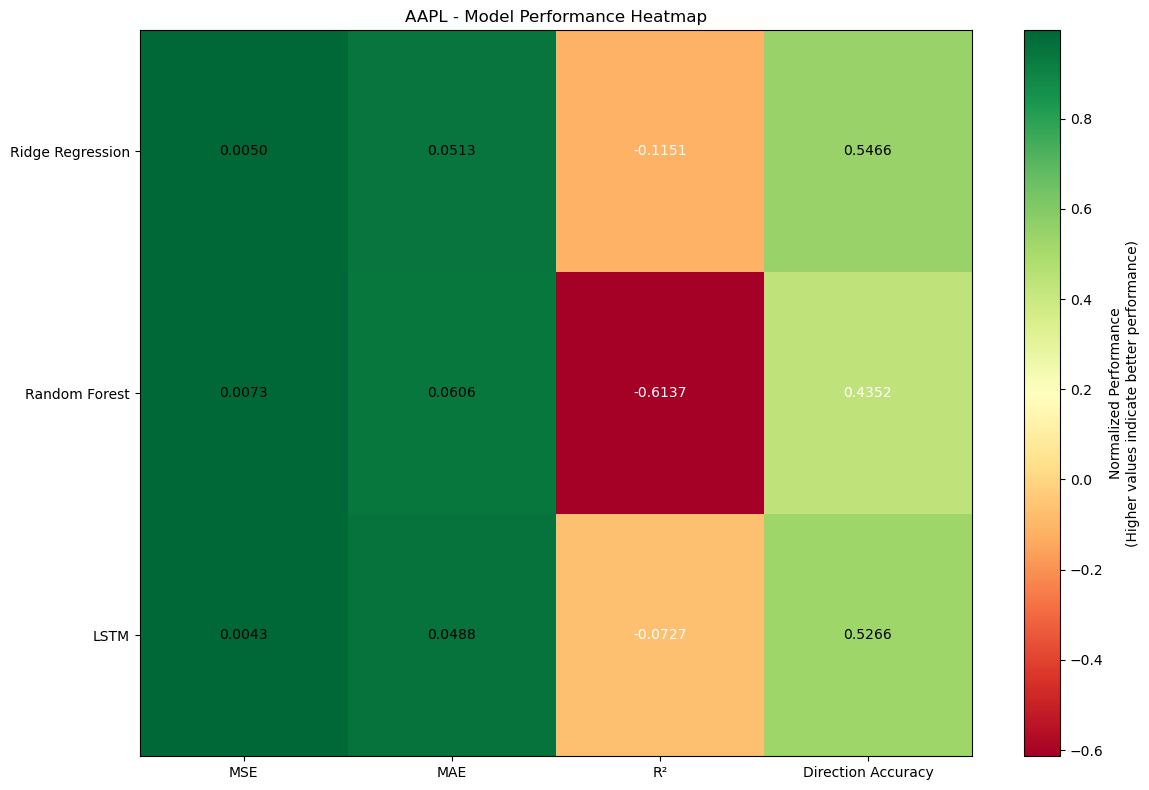

AAPL visualization completed!
Number of anomalies: 25 / 386
Trend prediction accuracy - Ridge: 0.9948, Random Forest: 0.9481

Creating visualizations for MSFT...


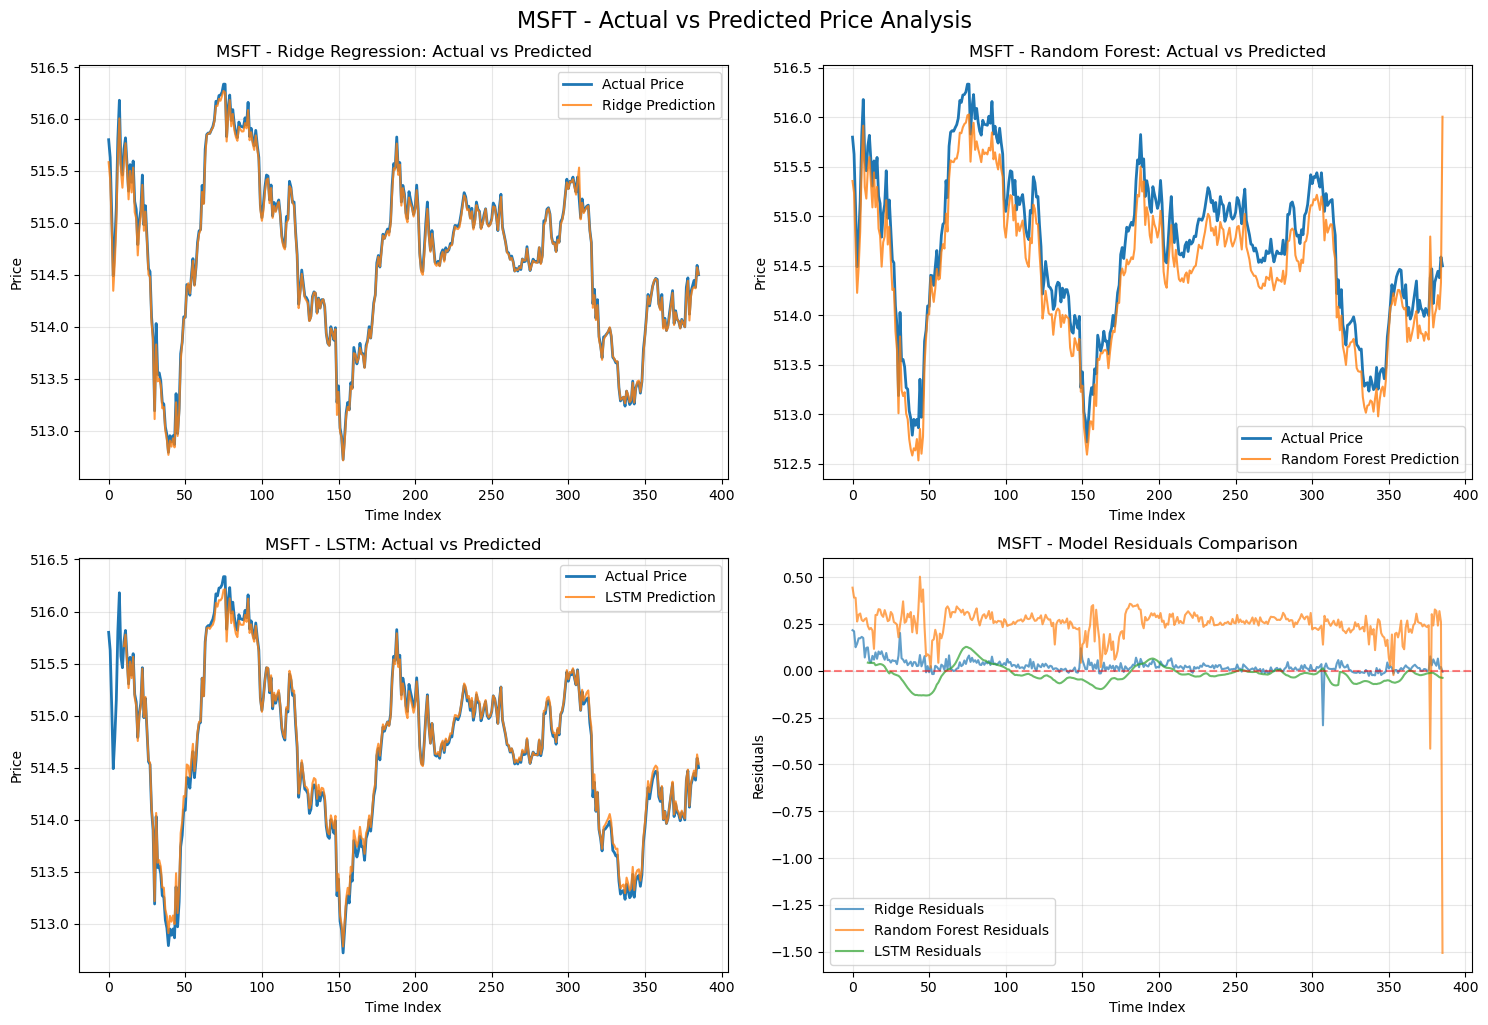

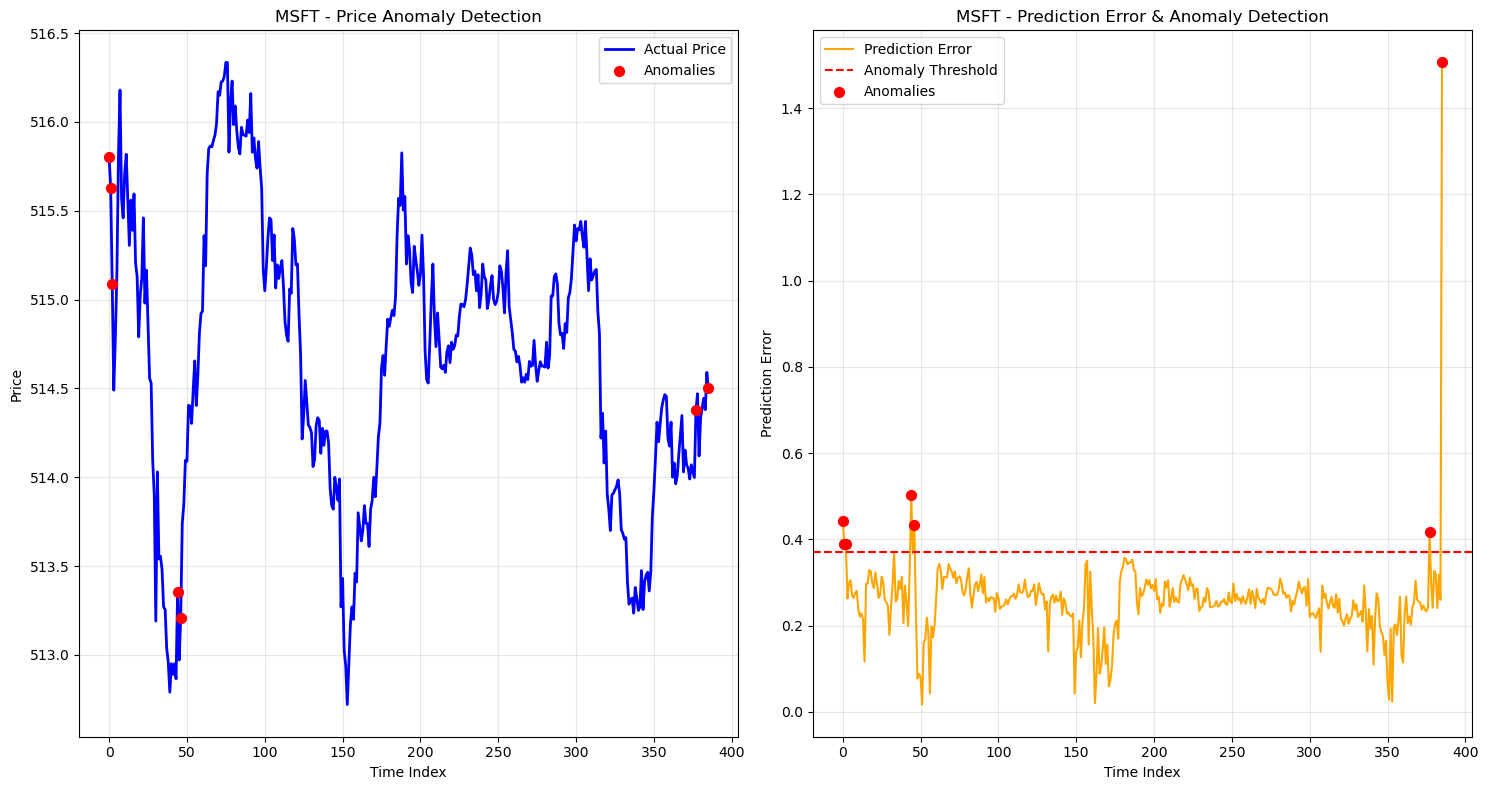

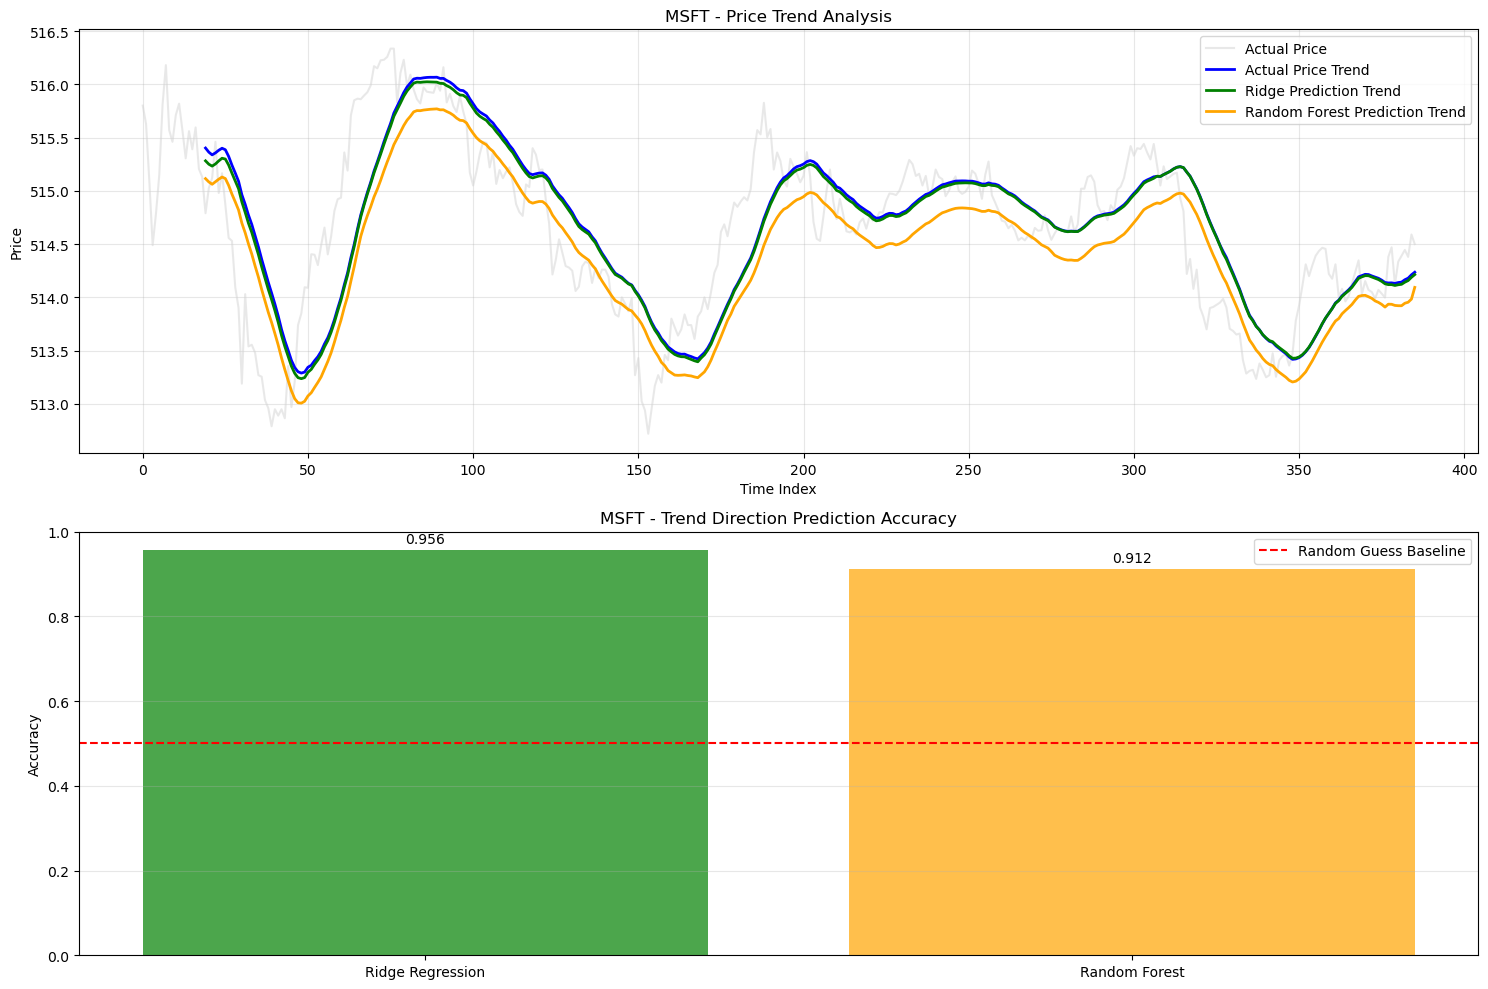

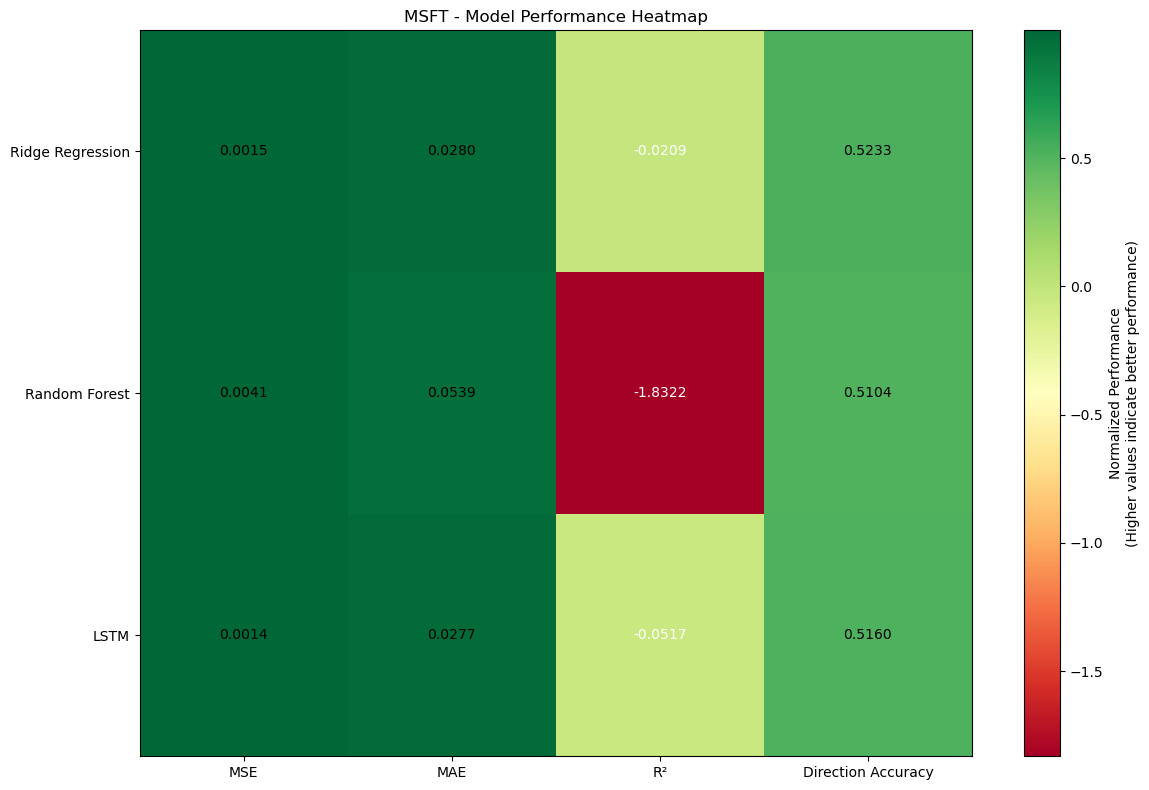

MSFT visualization completed!
Number of anomalies: 7 / 386
Trend prediction accuracy - Ridge: 0.9558, Random Forest: 0.9117

Creating visualizations for GOOGL...


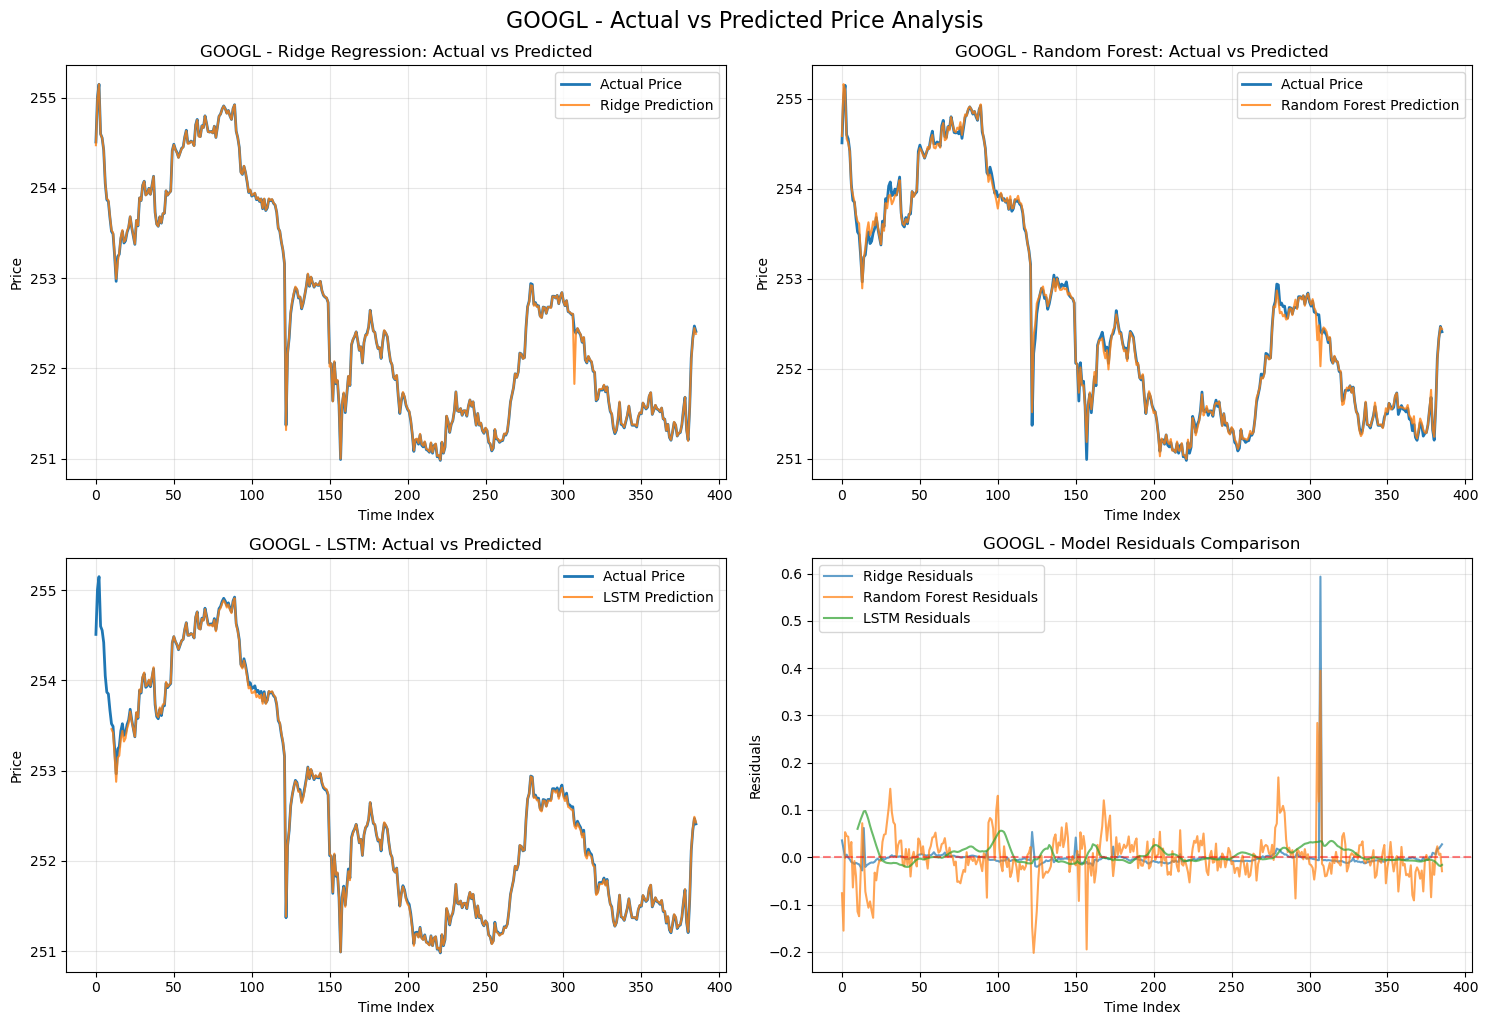

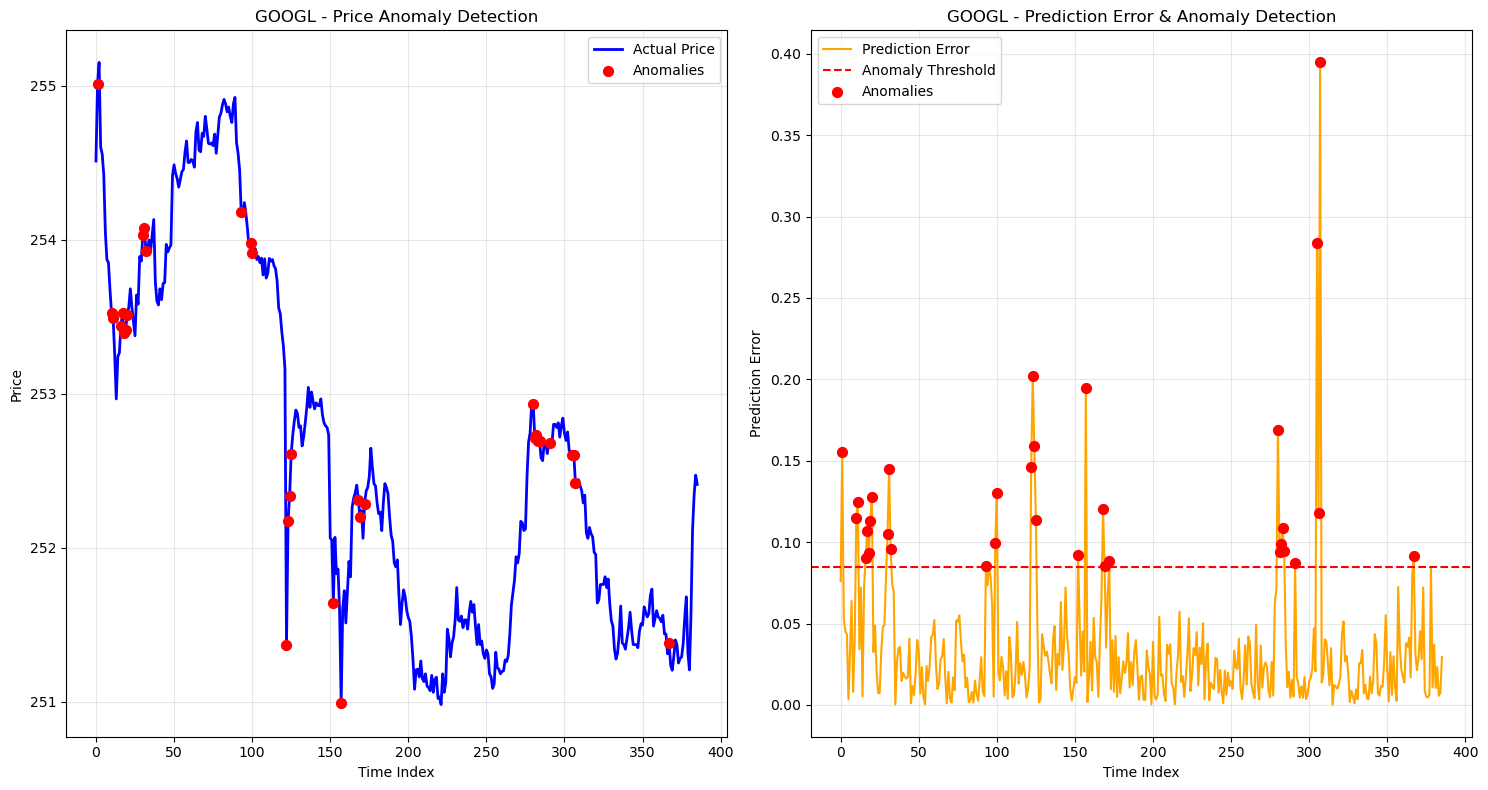

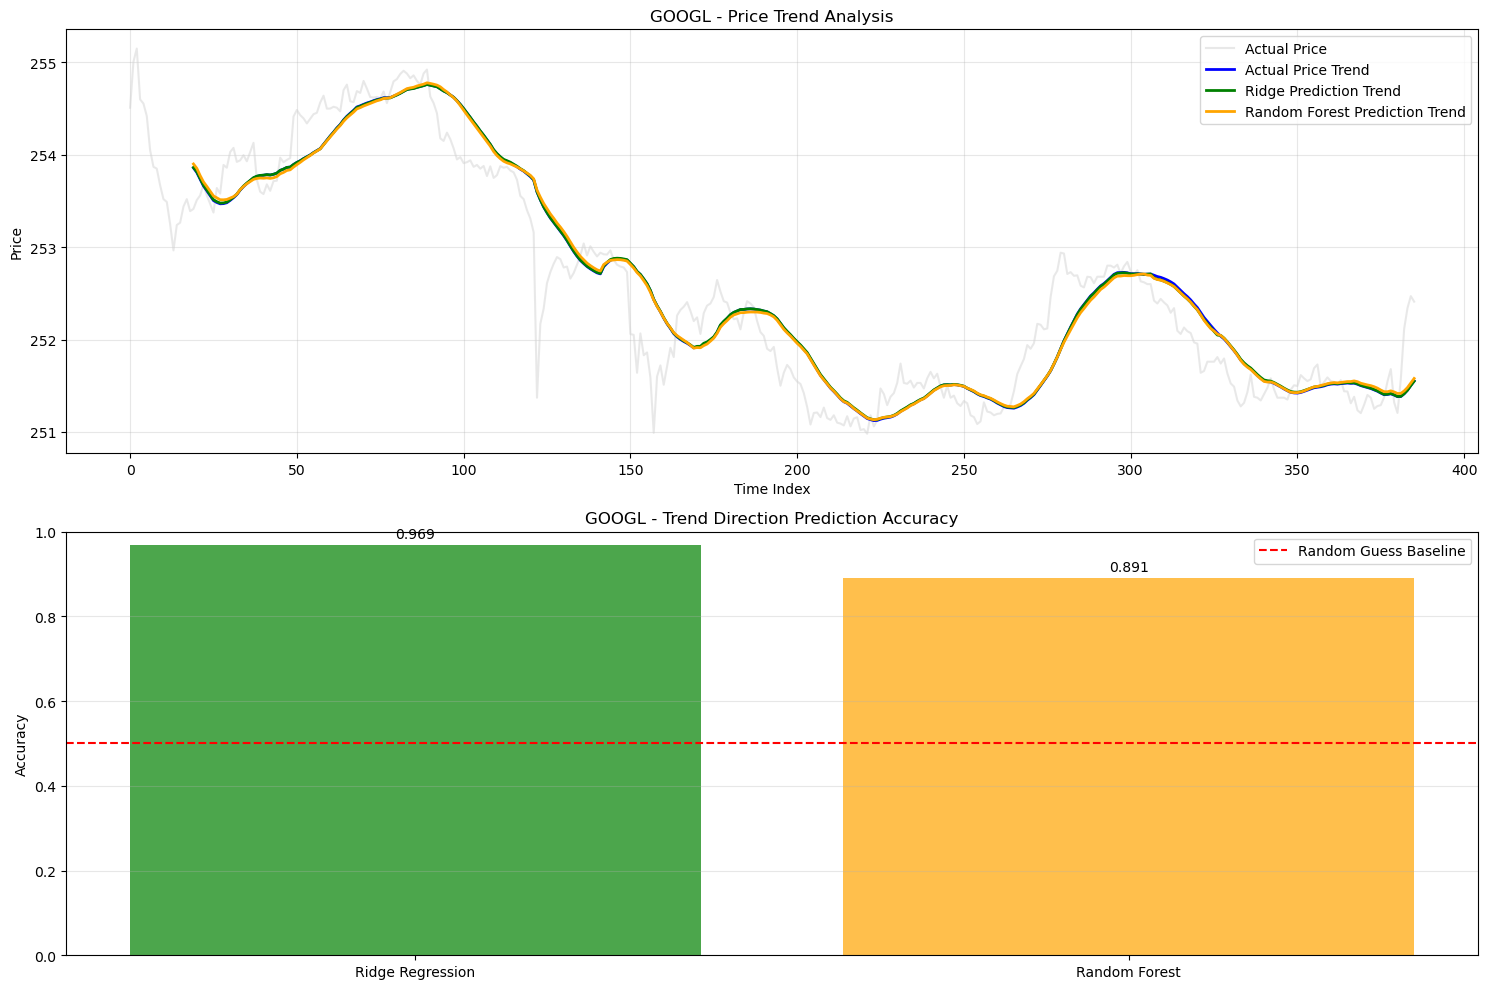

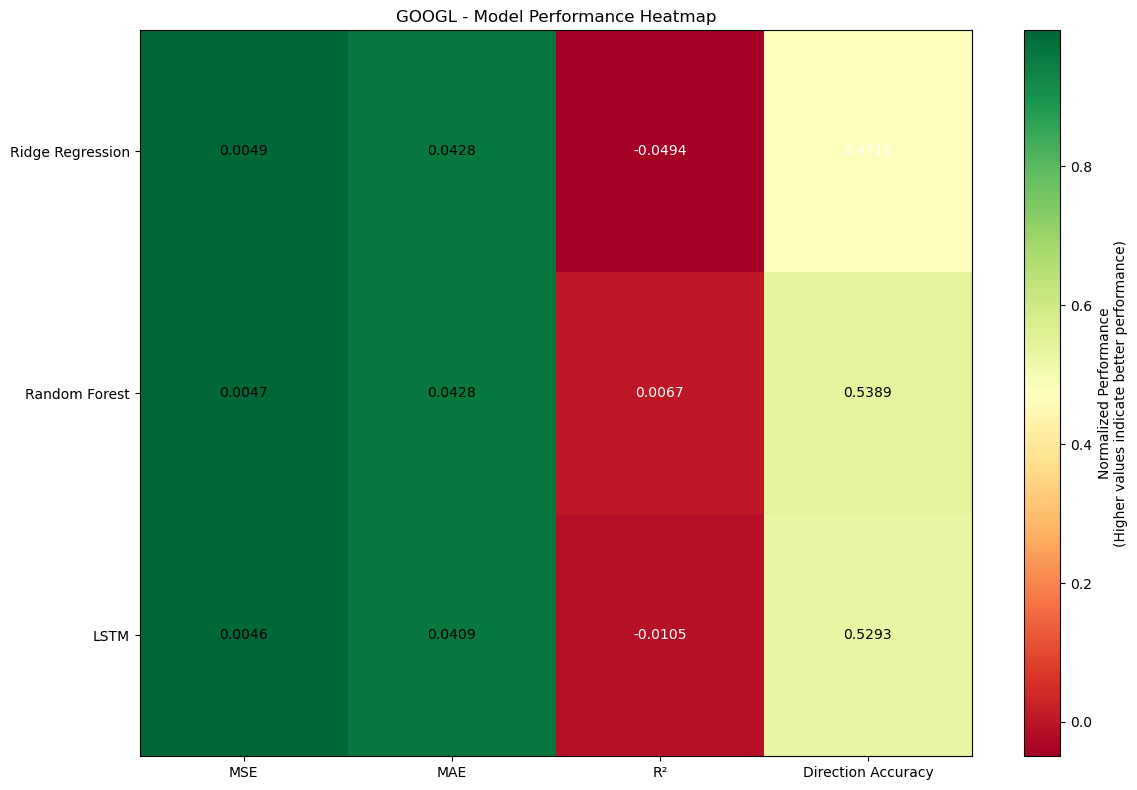

GOOGL visualization completed!
Number of anomalies: 33 / 386
Trend prediction accuracy - Ridge: 0.9688, Random Forest: 0.8909

Creating visualizations for AMZN...


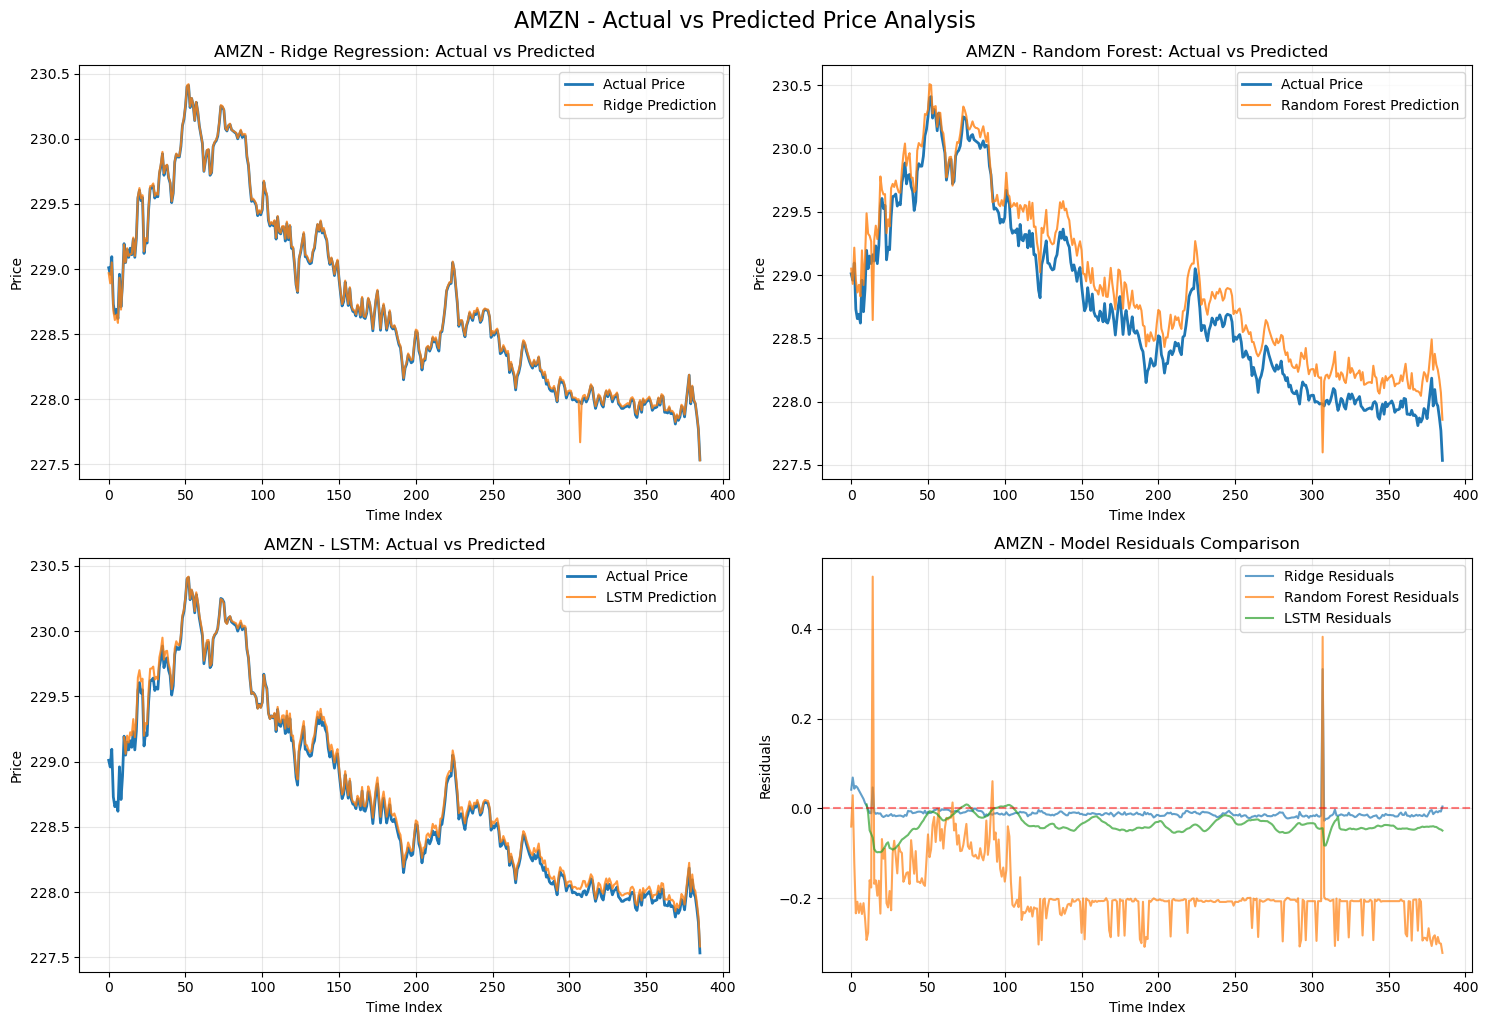

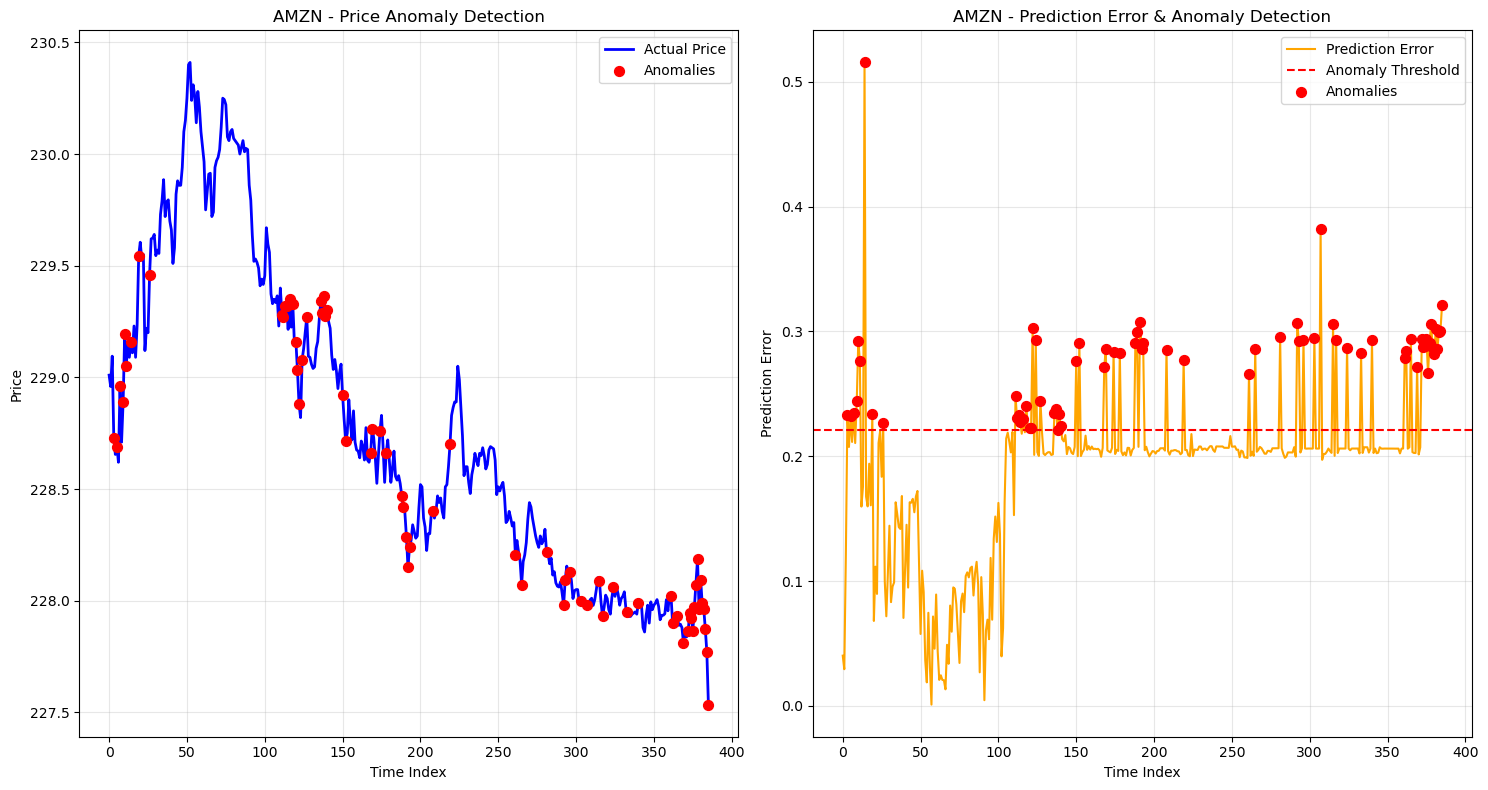

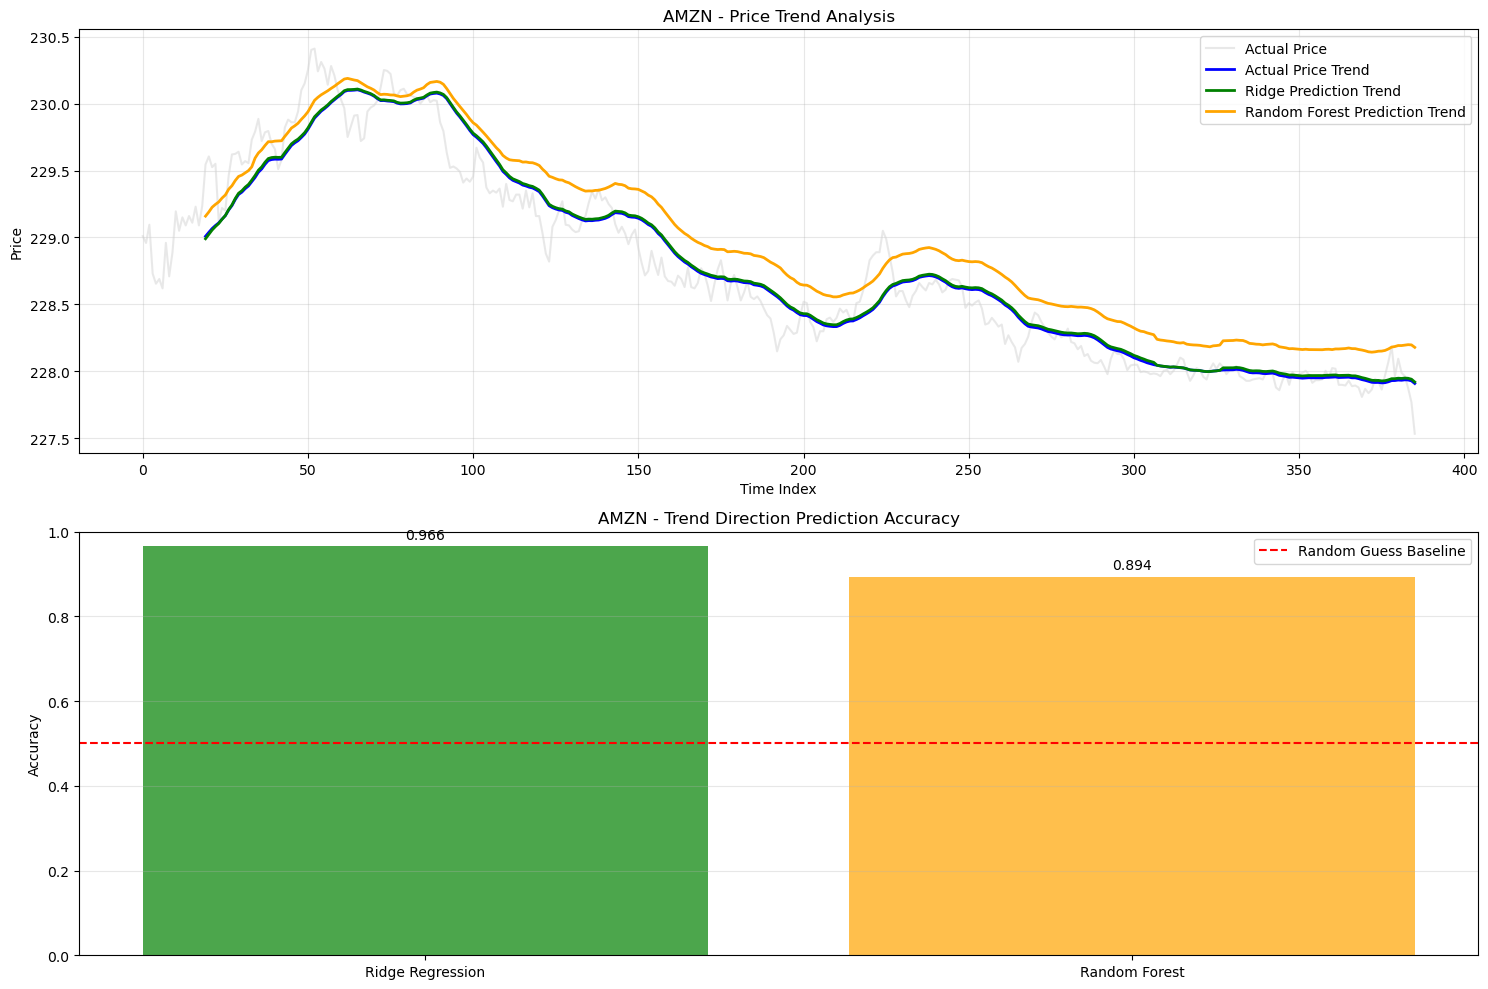

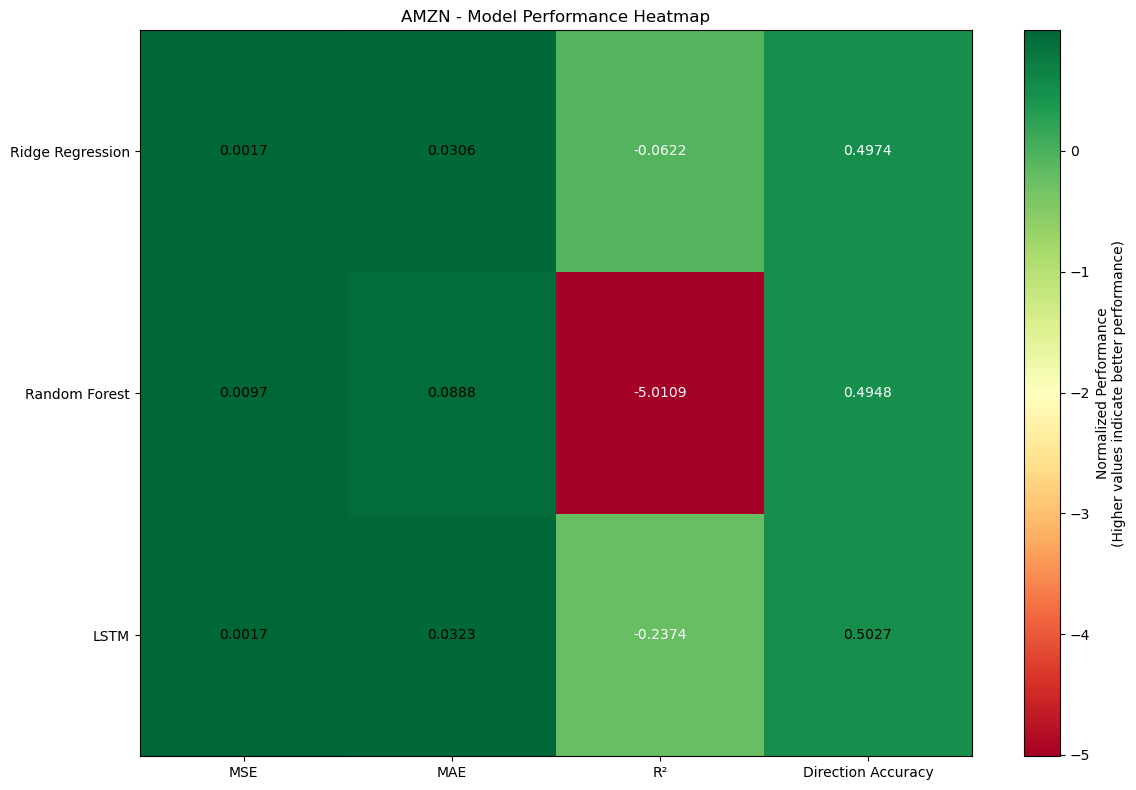

AMZN visualization completed!
Number of anomalies: 69 / 386
Trend prediction accuracy - Ridge: 0.9662, Random Forest: 0.8935

Creating visualizations for NVDA...


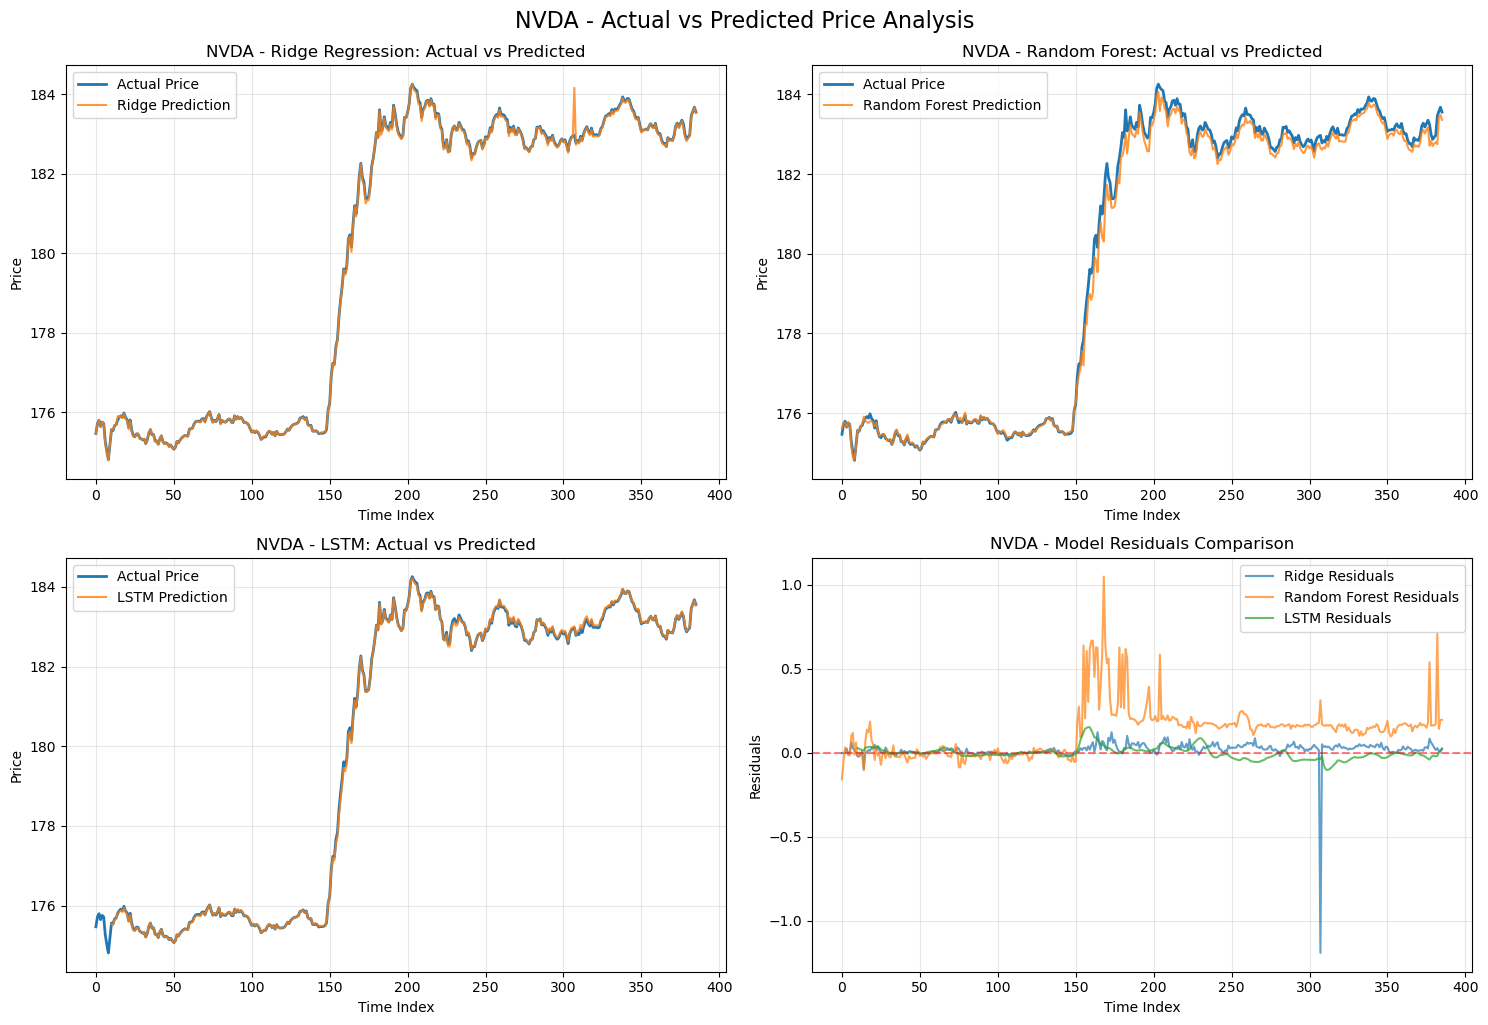

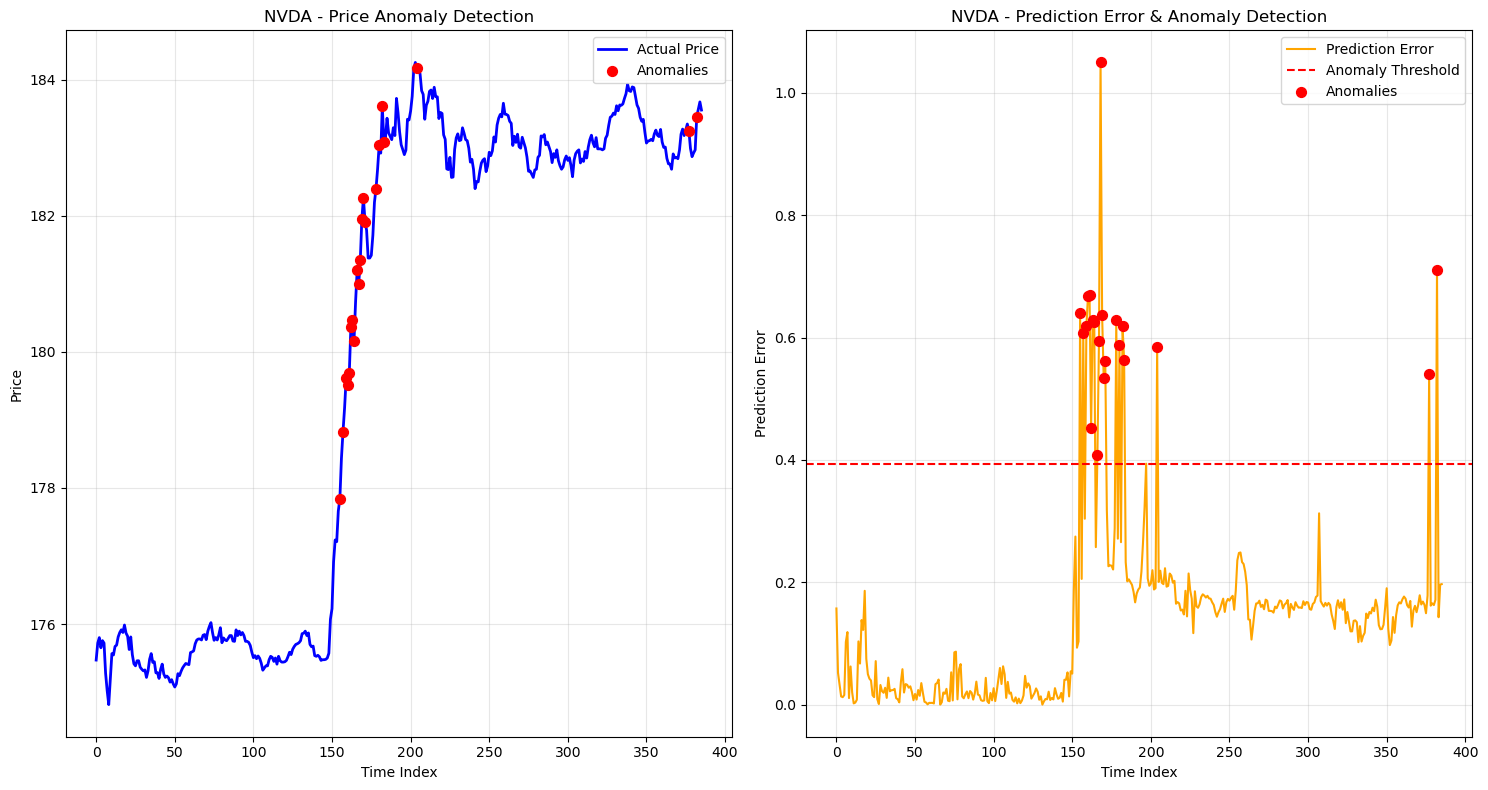

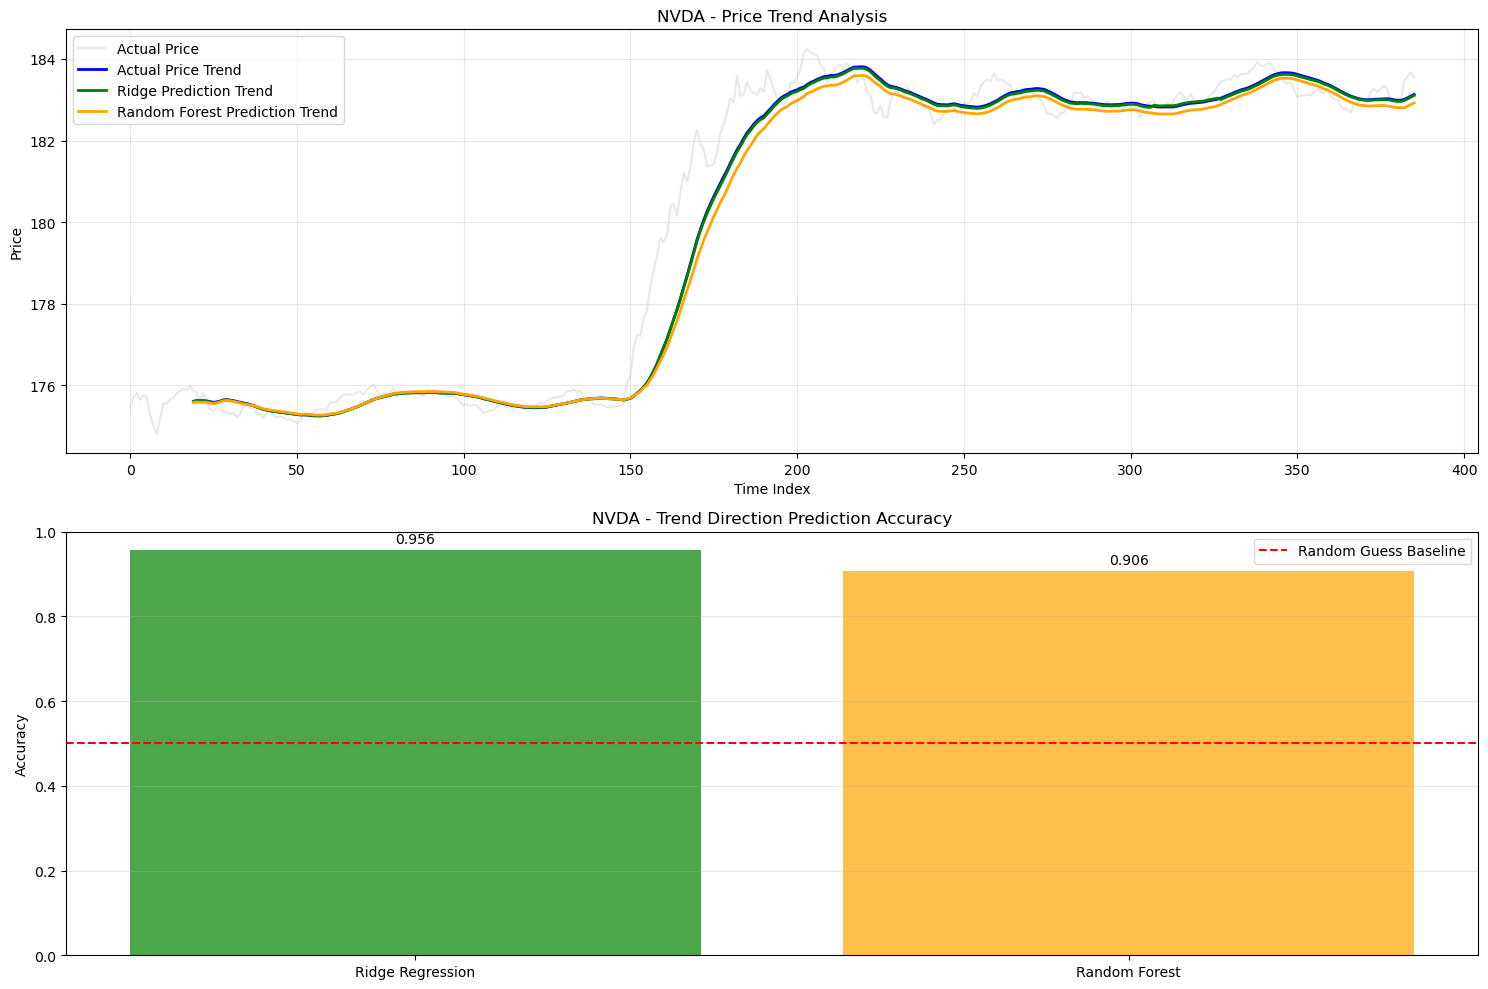

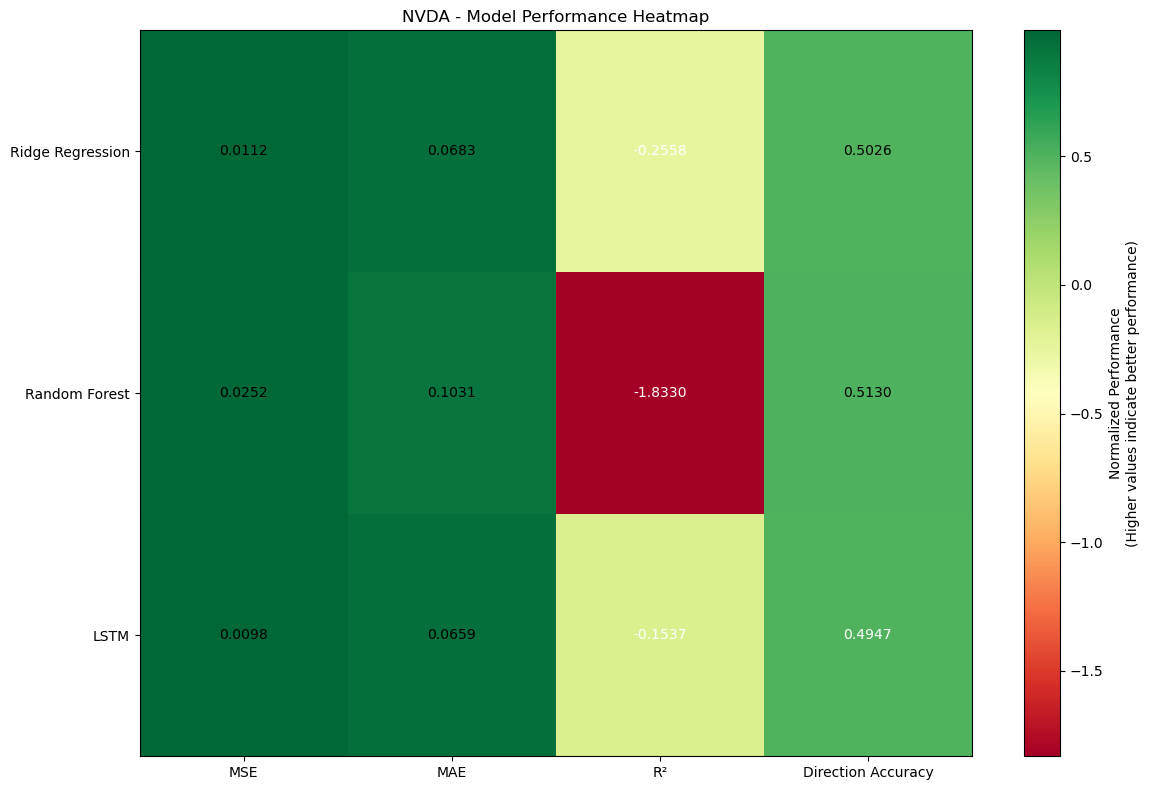

NVDA visualization completed!
Number of anomalies: 21 / 386
Trend prediction accuracy - Ridge: 0.9558, Random Forest: 0.9065


In [11]:
# Create directory for saving plots
if not os.path.exists('stock_plots'):
    os.makedirs('stock_plots')

# Create visualizations for each stock
for ticker in all_results:
    print(f"\nCreating visualizations for {ticker}...")
    
    # Create subdirectory for this stock
    stock_plot_dir = f'stock_plots/{ticker}'
    if not os.path.exists(stock_plot_dir):
        os.makedirs(stock_plot_dir)
    
    results = all_results[ticker]
    models = all_models[ticker]
    
    # Get test data
    X_test = results['X_test']
    y_test = results['y_test']
    
    # Get actual prices (using Close column)
    actual_prices = X_test['Close'].values
    
    # Create predicted prices for each model
    X_test_scaled = models['scaler'].transform(X_test)
    
    # Ridge Regression predictions
    y_pred_ridge = models['ridge'].predict(X_test_scaled)
    predicted_prices_ridge = actual_prices * (1 + y_pred_ridge/100)
    
    # Random Forest predictions
    y_pred_rf = models['rf'].predict(X_test_scaled)
    predicted_prices_rf = actual_prices * (1 + y_pred_rf/100)
    
    # LSTM predictions (if available)
    if models['lstm'] is not None:
        sequence_length = 10
        X_test_scaled_full = models['scaler'].transform(X_test)
        if len(X_test_scaled_full) >= sequence_length:
            X_test_seq, y_test_seq = [], []
            for i in range(len(X_test_scaled_full) - sequence_length):
                X_test_seq.append(X_test_scaled_full[i:i+sequence_length])
                y_test_seq.append(y_test.iloc[i+sequence_length])
            X_test_seq = np.array(X_test_seq)
            y_test_seq = np.array(y_test_seq)
            
            y_pred_lstm = models['lstm'].predict(X_test_seq, verbose=0).flatten()
            # Align actual prices
            actual_prices_lstm = actual_prices[sequence_length:]
            predicted_prices_lstm = actual_prices_lstm * (1 + y_pred_lstm/100)
        else:
            predicted_prices_lstm = None
            actual_prices_lstm = None
    else:
        predicted_prices_lstm = None
        actual_prices_lstm = None
    
    # Create time index (using test set time)
    time_index = range(len(actual_prices))
    
    # 1. Actual vs Predicted Prices Comparison
    plt.figure(figsize=(15, 10))
    
    # Subplot 1: Ridge Regression comparison
    plt.subplot(2, 2, 1)
    plt.plot(time_index, actual_prices, label='Actual Price', linewidth=2)
    plt.plot(time_index, predicted_prices_ridge, label='Ridge Prediction', alpha=0.8)
    plt.title(f'{ticker} - Ridge Regression: Actual vs Predicted')
    plt.xlabel('Time Index')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Subplot 2: Random Forest comparison
    plt.subplot(2, 2, 2)
    plt.plot(time_index, actual_prices, label='Actual Price', linewidth=2)
    plt.plot(time_index, predicted_prices_rf, label='Random Forest Prediction', alpha=0.8)
    plt.title(f'{ticker} - Random Forest: Actual vs Predicted')
    plt.xlabel('Time Index')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Subplot 3: LSTM comparison (if available)
    plt.subplot(2, 2, 3)
    plt.plot(time_index, actual_prices, label='Actual Price', linewidth=2)
    if predicted_prices_lstm is not None:
        lstm_time_index = time_index[sequence_length:]
        plt.plot(lstm_time_index, predicted_prices_lstm, label='LSTM Prediction', alpha=0.8)
        plt.title(f'{ticker} - LSTM: Actual vs Predicted')
    else:
        plt.title(f'{ticker} - LSTM: No Data Available')
    plt.xlabel('Time Index')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Subplot 4: Residuals comparison
    plt.subplot(2, 2, 4)
    residuals_ridge = actual_prices - predicted_prices_ridge
    residuals_rf = actual_prices - predicted_prices_rf
    
    plt.plot(time_index, residuals_ridge, label='Ridge Residuals', alpha=0.7)
    plt.plot(time_index, residuals_rf, label='Random Forest Residuals', alpha=0.7)
    
    if predicted_prices_lstm is not None:
        residuals_lstm = actual_prices_lstm - predicted_prices_lstm
        plt.plot(lstm_time_index, residuals_lstm, label='LSTM Residuals', alpha=0.7)
    
    plt.axhline(y=0, color='r', linestyle='--', alpha=0.5)
    plt.title(f'{ticker} - Model Residuals Comparison')
    plt.xlabel('Time Index')
    plt.ylabel('Residuals')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.suptitle(f'{ticker} - Actual vs Predicted Price Analysis', y=1.02, fontsize=16)
    
    # Save the figure
    plt.savefig(f'{stock_plot_dir}/{ticker}_comparison.png', dpi=300, bbox_inches='tight')
    
    # Show the figure
    plt.show()
    
    # 2. Anomaly Detection Visualization
    plt.figure(figsize=(15, 8))
    
    # Calculate prediction errors (using Random Forest as baseline)
    prediction_errors = np.abs(actual_prices - predicted_prices_rf)
    
    # Use IQR method to detect anomalies
    Q1 = np.percentile(prediction_errors, 25)
    Q3 = np.percentile(prediction_errors, 75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    
    anomalies = prediction_errors > upper_bound
    
    plt.subplot(1, 2, 1)
    plt.plot(time_index, actual_prices, label='Actual Price', color='blue', linewidth=2)
    plt.scatter(np.where(anomalies)[0], actual_prices[anomalies], 
               color='red', s=50, zorder=5, label='Anomalies')
    plt.title(f'{ticker} - Price Anomaly Detection')
    plt.xlabel('Time Index')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1, 2, 2)
    plt.plot(time_index, prediction_errors, label='Prediction Error', color='orange')
    plt.axhline(y=upper_bound, color='red', linestyle='--', label='Anomaly Threshold')
    plt.scatter(np.where(anomalies)[0], prediction_errors[anomalies], 
               color='red', s=50, zorder=5, label='Anomalies')
    plt.title(f'{ticker} - Prediction Error & Anomaly Detection')
    plt.xlabel('Time Index')
    plt.ylabel('Prediction Error')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save the figure
    plt.savefig(f'{stock_plot_dir}/{ticker}_anomaly_detection.png', dpi=300, bbox_inches='tight')
    
    # Show the figure
    plt.show()
    
    # 3. Trend Analysis Visualization
    plt.figure(figsize=(15, 10))
    
    # Calculate moving averages to identify trends
    window_size = min(20, len(actual_prices) // 10)  # Adaptive window size
    
    actual_ma = pd.Series(actual_prices).rolling(window=window_size).mean()
    pred_ridge_ma = pd.Series(predicted_prices_ridge).rolling(window=window_size).mean()
    pred_rf_ma = pd.Series(predicted_prices_rf).rolling(window=window_size).mean()
    
    plt.subplot(2, 1, 1)
    plt.plot(time_index, actual_prices, label='Actual Price', alpha=0.5, color='lightgray')
    plt.plot(time_index, actual_ma, label='Actual Price Trend', linewidth=2, color='blue')
    plt.plot(time_index, pred_ridge_ma, label='Ridge Prediction Trend', linewidth=2, color='green')
    plt.plot(time_index, pred_rf_ma, label='Random Forest Prediction Trend', linewidth=2, color='orange')
    plt.title(f'{ticker} - Price Trend Analysis')
    plt.xlabel('Time Index')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Trend direction accuracy
    actual_direction = np.sign(np.diff(actual_prices))
    pred_ridge_direction = np.sign(np.diff(predicted_prices_ridge))
    pred_rf_direction = np.sign(np.sign(np.diff(predicted_prices_rf)))
    
    # Calculate trend prediction accuracy
    ridge_trend_accuracy = np.mean(actual_direction == pred_ridge_direction)
    rf_trend_accuracy = np.mean(actual_direction == pred_rf_direction)
    
    plt.subplot(2, 1, 2)
    categories = ['Ridge Regression', 'Random Forest']
    accuracies = [ridge_trend_accuracy, rf_trend_accuracy]
    colors = ['green', 'orange']
    
    bars = plt.bar(categories, accuracies, color=colors, alpha=0.7)
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guess Baseline')
    plt.title(f'{ticker} - Trend Direction Prediction Accuracy')
    plt.ylabel('Accuracy')
    plt.ylim(0, 1)
    
    # Add value labels on bars
    for bar, accuracy in zip(bars, accuracies):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{accuracy:.3f}', ha='center', va='bottom')
    
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    
    # Save the figure
    plt.savefig(f'{stock_plot_dir}/{ticker}_trend_analysis.png', dpi=300, bbox_inches='tight')
    
    # Show the figure
    plt.show()
    
    # 4. Model Performance Heatmap
    plt.figure(figsize=(12, 8))
    
    # Prepare performance metrics data
    metrics_data = {
        'MSE': [results['ridge_metrics'][0], results['rf_metrics'][0], 
                results['lstm_metrics'][0] if models['lstm'] is not None else np.nan],
        'MAE': [results['ridge_metrics'][1], results['rf_metrics'][1], 
                results['lstm_metrics'][1] if models['lstm'] is not None else np.nan],
        'R²': [results['ridge_metrics'][2], results['rf_metrics'][2], 
               results['lstm_metrics'][2] if models['lstm'] is not None else np.nan],
        'Direction Accuracy': [results['ridge_metrics'][3], results['rf_metrics'][3], 
                   results['lstm_metrics'][3] if models['lstm'] is not None else np.nan]
    }
    
    models_list = ['Ridge Regression', 'Random Forest', 'LSTM']
    metrics_df = pd.DataFrame(metrics_data, index=models_list)
    
    # For MSE and MAE, lower values are better, we take reciprocal for color mapping
    normalized_metrics = metrics_df.copy()
    normalized_metrics[['MSE', 'MAE']] = 1 / (1 + normalized_metrics[['MSE', 'MAE']])
    
    # Create heatmap
    im = plt.imshow(normalized_metrics.values, cmap='RdYlGn', aspect='auto')
    
    # Set axis labels
    plt.xticks(range(len(metrics_df.columns)), metrics_df.columns)
    plt.yticks(range(len(metrics_df.index)), metrics_df.index)
    
    # Add values to each cell
    for i in range(len(metrics_df.index)):
        for j in range(len(metrics_df.columns)):
            plt.text(j, i, f'{metrics_df.iloc[i, j]:.4f}', 
                    ha='center', va='center', fontsize=10,
                    color='white' if normalized_metrics.iloc[i, j] < 0.5 else 'black')
    
    plt.colorbar(im, label='Normalized Performance\n(Higher values indicate better performance)')
    plt.title(f'{ticker} - Model Performance Heatmap')
    plt.tight_layout()
    
    # Save the figure
    plt.savefig(f'{stock_plot_dir}/{ticker}_performance_heatmap.png', dpi=300, bbox_inches='tight')
    
    # Show the figure
    plt.show()
    
    print(f"{ticker} visualization completed!")
    print(f"Number of anomalies: {np.sum(anomalies)} / {len(anomalies)}")
    print(f"Trend prediction accuracy - Ridge: {ridge_trend_accuracy:.4f}, Random Forest: {rf_trend_accuracy:.4f}")